# Verification of S_quantum Metrics
Independent used for the validating **the accuracy of calculation logic only**. 

It does not decide whether a rewrite should be accepted as semantically equivalent.

The notebook has 3 independent parts:

1. **Part I — core : s_quantum axes:** \(s_g\), sequence-based \(s_s\), and \(s_f\).
2. **Part II — explore : interaction-based \(s_s\)** I use 2 algorithm（WL and edge Jaccard）to measure the similarity of the qubit-interaction graph, including saturation test. 
3. **Part III- test: Strip diagnostic** compare with 2 implementations "strip before DAG" vs "skip nodes in the full DAG", including DAG visual figure.


# Part I — Full test contract for \(s_g\), sequence-based \(s_s\), and \(f\)



### 1. Gate-count similarity \(s_g\)

| Scenario | Expected calculation |
|---|---|
| Identical gate histograms | `cosine=1`, `ratio=1`, \(s_g=1\) |
| Different non-proportional histograms | `ratio=None`; \(s_g\) equals cosine and is normally between 0 and 1 |
| No shared gate types | `cosine=0`, `ratio=None`, \(s_g=0\) |
| Candidate is exactly 2× reference | `cosine=1`, symmetric `ratio=2`, \(s_g=NaN\) |
| Candidate is exactly 0.5× reference | `cosine=1`, symmetric `ratio=2`, \(s_g=NaN\) |
| Empty/unavailable circuit | all primary gate metrics are `NaN`/`None` |
| Only measure/reset/barrier/delay differs | these operations are excluded; \(s_g\) is unchanged |
| AST loop vs executed circuit | AST diagnostic may under-count; circuit-based value is primary |

### 2. Sequence structure \(s_s\)

For each canonical qubit line, the implementation calculates LCS coverage and 2-gram coverage, then

\[
s_s=\frac{s_{\mathrm{LCS}}+s_{\mathrm{kgram}}}{2}.
\]

| Scenario | Expected calculation |
|---|---|
| Same gate sequence on every wire | LCS=1, k-gram=1, \(s_s=1\) |
| Reorder independent gates on different wires | per-wire sequences remain unchanged; \(s_s=1\) |
| Reorder gates on the same wire | LCS and/or k-gram decreases; \(s_s<1\) |
| Strategy-A decomposition in raw view | usually \(s_s<1\) |
| Same decomposition after common-basis transpilation | may become \(s_s=1\) |
| Only measure/reset/barrier/delay differs | excluded from structural view; \(s_s\) unchanged |
| Circuit construction fails | structural values are `NaN`/`None` |

### 3. Functional similarity \(f\)

| Circuit type | Required route | Expected equivalent result |
|---|---|---|
| No measurement and no reset | process fidelity | \(f\approx1\), up to floating-point tolerance |
| Terminal-only measurement | preserve mapping; strip terminal measurement; exact Statevector output probabilities; TVD | \(D_{\mathrm{TVD}}\approx0\), \(f\approx1\) |
| Mid-circuit measurement or reset | preserve measurement/reset; 32,768-shot TVD | \(f=1-D_{\mathrm{TVD}}\), normally close to but not exactly 1 |

These tests inspect the route and numeric result. Acceptance thresholds \(\epsilon\) and \(\tau_{\mathrm{mid}}\) belong to equivalence classification, not this calculation test.


## Planned case table

| ID | Type | Source task | Modification or relation | Main expected outputs |
|---|---|---|---|---|
| N1 | Normal | `qiskitHumanEval/3-A` | H replaced by RZ–SX–RZ | raw \(s_g,s_s<1\); transpiled values expected to approach/equal 1; terminal exact \(f=1\) |
| N2 | Normal | `02-B` | H(2) and X(1) reordered across wires | \(s_g=1,s_s=1\), terminal exact \(f=1\) |
| N3 | Normal | `01-B` | Z and CZ reordered on the same wires | \(s_g=1\), but sequence \(s_s<1\), terminal exact \(f=1\) |
| N4 | Normal | `qiskitHumanEval/13-A` | U decomposed into RZ–RY–RZ | process-fidelity route, \(f=1\) |
| N5 | Normal | `qiskitHumanEval/66-A` | terminal-only W-state rewrite | exact-terminal route, \(f=1\) |
| N6 | Normal | `qiskitHumanEval/67-A` | mid-circuit CHSH rewrite | shot route, \(f\) close to 1 |
| A1 | Artificial anomaly | `qiskitHumanEval/13-A` rewrite | change only `RY(pi/2)` to `RY(pi/3)` | \(s_g=s_s=1\), but process \(f<1\) (about 0.933) |
| A2 | Artificial anomaly | `02-B` rewrite | reverse q-to-c measurement mapping | \(s_g=s_s=1\), but exact-terminal \(f<1\) |
| A3 | Artificial anomaly | `qiskitHumanEval/66-A` rewrite | change only the state-preparation RY angle | \(s_g=s_s=1\), but exact-terminal \(f<1\) |
| A4 | Artificial anomaly | `qiskitHumanEval/67-A` rewrite | change Bob's RY angle for `bob=0` | \(s_g=s_s=1\), but shot-based \(f<1\) |
| A5 | Artificial anomaly | synthetic circuits | candidate has exactly twice every gate count | cosine=1, ratio=2 in both directions, primary \(s_g=NaN\) |

For A1–A4, the accepted rewrite is used as the correct reference and a one-line mutant is used as the candidate. This isolates the property being tested: the structural representation is identical while the functional behaviour changes.


## Part I — Code

In [3]:
from pathlib import Path
import importlib.util
import json
import math
import re
from collections import Counter

import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_DIR = Path("/Users/milly/Desktop/LLM-based-Q-generation")
UTIL_PATH   = PROJECT_DIR / "s_quantum_utils.py"
MAIN_JSON   = PROJECT_DIR / "exp1_results" / "qmri_rewrite_results_r5.json"
EXTRA_JSON  = PROJECT_DIR / "exp1_results" / "qmri_rewrite_B_nonSI_candidates_15.json"

for p in [UTIL_PATH, MAIN_JSON, EXTRA_JSON]:
    assert p.exists(), f"Not found: {p}"

spec = importlib.util.spec_from_file_location("s_quantum_utils", UTIL_PATH)
s_quantum_utils = importlib.util.module_from_spec(spec)
spec.loader.exec_module(s_quantum_utils)
qmri = s_quantum_utils  # alias used in subsequent cells

main_records  = json.loads(MAIN_JSON.read_text(encoding="utf-8"))
extra_records = json.loads(EXTRA_JSON.read_text(encoding="utf-8"))

# Main r5 takes precedence; the extra file fills any missing rewrite IDs.
RECORDS = {r["rewrite_id"]: r for r in extra_records}
RECORDS.update({r["rewrite_id"]: r for r in main_records})

print("Utility:", UTIL_PATH)
print("Main JSON:", MAIN_JSON, f"({len(main_records)} records)")
print("Extra JSON:", EXTRA_JSON, f"({len(extra_records)} records)")
print("Historical main statuses:", Counter(r.get("status") for r in main_records))

Utility: /Users/milly/Desktop/LLM-based-Q-generation/s_quantum_utils.py
Main JSON: /Users/milly/Desktop/LLM-based-Q-generation/exp1_results/qmri_rewrite_results_r5.json (125 records)
Extra JSON: /Users/milly/Desktop/LLM-based-Q-generation/exp1_results/qmri_rewrite_B_nonSI_candidates_15.json (15 records)
Historical main statuses: Counter({'pass': 96, 'skip': 18, 'failed': 11})


## Shared execution and reporting helpers

The output table deliberately shows raw and transpiled views separately. `None` is displayed as `NaN` by pandas.

For the selected parameterised functions, fixed kwargs are used so the test is reproducible. These kwargs are part of the test fixture, not an experimental average.


In [2]:
CASE_KWARGS = {
    "qiskitHumanEval/67": {"alice": 0, "bob": 0},
}

OUTPUT_FIELDS = [
    "s_gate_raw", "s_gate_raw_cosine", "s_gate_raw_ratio",
    "s_struct_raw", "s_struct_raw_lcs", "s_struct_raw_kgram",
    "s_gate_transpiled", "s_gate_transpiled_cosine", "s_gate_transpiled_ratio",
    "s_struct_transpiled", "s_struct_transpiled_lcs", "s_struct_transpiled_kgram",
    "f", "f_tvd", "f_min_score", "functional_method", "functional_status",
    "raw_status", "transpiled_status",
]


def resolved_kwargs(task_id):
    tokens = qmri.TASK_EXTRA_ARGS.get(task_id, {})
    values = {key: qmri.resolve_arg(value) for key, value in tokens.items()}
    values.update(CASE_KWARGS.get(task_id, {}))
    return values


def original_full_code(record):
    return qmri.reconstruct_full_code(
        record["original_prompt_text"],
        record["canonical_solution_text"],
    )


def execute_code(record, code):
    return qmri.exec_code(
        record["entry_point"],
        resolved_kwargs(record["real_task_id"]),
        code,
    )


def execute_record(record):
    original_code = original_full_code(record)
    rewrite_code = record["rewritten_code"]
    original_qc, original_error = execute_code(record, original_code)
    rewrite_qc, rewrite_error = execute_code(record, rewrite_code)
    return {
        "original_code": original_code,
        "rewrite_code": rewrite_code,
        "original_qc": original_qc,
        "rewrite_qc": rewrite_qc,
        "original_error": original_error,
        "rewrite_error": rewrite_error,
    }


def pair_metrics(reference_qc, candidate_qc, reference_code, candidate_code):
    return qmri.compute_pair_metrics(
        reference_qc=reference_qc,
        candidate_qc=candidate_qc,
        reference_code=reference_code,
        candidate_code=candidate_code,
    )


def compact_row(case_id, record_id, metrics, note=""):
    row = {"case": case_id, "record": record_id, "note": note}
    row.update({field: metrics.get(field) for field in OUTPUT_FIELDS})
    return row


def is_close(value, target=1.0, atol=1e-8):
    return value is not None and math.isfinite(float(value)) and abs(float(value) - target) <= atol


def show_case(case_id, record_id, expected, metrics, errors=None):
    print(f"\n{case_id} — {record_id}")
    print("Expected:", expected)
    if errors:
        print("Execution errors:", errors)
    display(pd.DataFrame([compact_row(case_id, record_id, metrics)]))


## Part I-A — Normal JSON rewrite pairs

Run these first. A failure may mean either:

1. the utility route is incorrect;
2. the JSON pair cannot be reconstructed with the current environment/Qiskit version; or
3. the expected structural property was not satisfied by the actual transpiler output.

Do not silently discard failures; keep the execution status beside the metric values.


### N1 — Strategy A, raw change followed by common-basis convergence

Task: `qiskitHumanEval/3-A`.

- Raw canonical contains `H`; rewrite contains `RZ–SX–RZ`, so raw \(s_g,s_s<1\).
- After common-basis transpilation, both sides are expected to use the same decomposition, so transpiled \(s_g,s_s\) should be 1 or numerically very close.
- Measurement is terminal-only, so `functional_method` must be `exact_terminal_output_probability`, with \(f\approx1\).


In [3]:
normal_results = {}

record = RECORDS["qiskitHumanEval/3-A"]
executed = execute_record(record)
metrics = pair_metrics(
    executed["original_qc"], executed["rewrite_qc"],
    executed["original_code"], executed["rewrite_code"],
)
normal_results["N1"] = metrics
show_case(
    "N1", record["rewrite_id"],
    "raw sg/ss < 1; transpiled sg/ss ≈ 1; exact-terminal f ≈ 1",
    metrics,
    [executed["original_error"], executed["rewrite_error"]],
)


/Users/milly/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(



N1 — qiskitHumanEval/3-A
Expected: raw sg/ss < 1; transpiled sg/ss ≈ 1; exact-terminal f ≈ 1
Execution errors: [None, None]


,case,record,note,s_gate_raw,s_gate_raw_cosine,s_gate_raw_ratio,s_struct_raw,s_struct_raw_lcs,s_struct_raw_kgram,s_gate_transpiled,...,s_struct_transpiled,s_struct_transpiled_lcs,s_struct_transpiled_kgram,f,f_tvd,f_min_score,functional_method,functional_status,raw_status,transpiled_status
0,N1,qiskitHumanEval/3-A,,0.596285,0.596285,None,0.861111,0.888889,0.833333,1.0,...,1.0,1.0,1.0,1.0,0.0,1.0,exact_terminal_output_probability,ok,ok,ok


### N2 — Strategy B across different wires

Task: `02-B`.

`H(2)` and `X(1)` exchange their global order but each wire retains the same sequence. Expected:

\[
s_g=1,\qquad s_{\mathrm{LCS}}=s_{\mathrm{kgram}}=s_s=1,
\]

and terminal exact \(f\approx1\).


In [4]:
record = RECORDS["02-B"]
executed = execute_record(record)
metrics = pair_metrics(
    executed["original_qc"], executed["rewrite_qc"],
    executed["original_code"], executed["rewrite_code"],
)
normal_results["N2"] = metrics
show_case(
    "N2", record["rewrite_id"],
    "raw/transpiled sg=1 and sequence ss=1; exact-terminal f≈1",
    metrics,
    [executed["original_error"], executed["rewrite_error"]],
)



N2 — 02-B
Expected: raw/transpiled sg=1 and sequence ss=1; exact-terminal f≈1
Execution errors: [None, None]


,case,record,note,s_gate_raw,s_gate_raw_cosine,s_gate_raw_ratio,s_struct_raw,s_struct_raw_lcs,s_struct_raw_kgram,s_gate_transpiled,...,s_struct_transpiled,s_struct_transpiled_lcs,s_struct_transpiled_kgram,f,f_tvd,f_min_score,functional_method,functional_status,raw_status,transpiled_status
0,N2,02-B,,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,0.0,1.0,exact_terminal_output_probability,ok,ok,ok


### N3 — Strategy B on the same wires

Task: `01-B`.

`Z` and `CZ` are reordered on the same qubit lines. Gate counts are unchanged, but local order changes. Expected:

- \(s_g=1\);
- LCS and/or k-gram below 1, hence \(s_s<1\);
- terminal exact \(f\approx1\).

This is the counterexample to “every Strategy-B rewrite has \(s_s=1\)”.


In [5]:
record = RECORDS["01-B"]
executed = execute_record(record)
metrics = pair_metrics(
    executed["original_qc"], executed["rewrite_qc"],
    executed["original_code"], executed["rewrite_code"],
)
normal_results["N3"] = metrics
show_case(
    "N3", record["rewrite_id"],
    "sg=1; sequence ss<1; exact-terminal f≈1",
    metrics,
    [executed["original_error"], executed["rewrite_error"]],
)



N3 — 01-B
Expected: sg=1; sequence ss<1; exact-terminal f≈1
Execution errors: [None, None]


,case,record,note,s_gate_raw,s_gate_raw_cosine,s_gate_raw_ratio,s_struct_raw,s_struct_raw_lcs,s_struct_raw_kgram,s_gate_transpiled,...,s_struct_transpiled,s_struct_transpiled_lcs,s_struct_transpiled_kgram,f,f_tvd,f_min_score,functional_method,functional_status,raw_status,transpiled_status
0,N3,01-B,,1.0,1.0,1.0,0.756944,0.888889,0.625,1.0,...,0.93836,0.948148,0.928571,1.0,0.0,1.0,exact_terminal_output_probability,ok,ok,ok


### N4 — No-measurement functional route

Task: `qiskitHumanEval/13-A`.

Expected `functional_method="process_fidelity"` and \(f\approx1\). Raw structural values need not equal 1 because a `U` gate is replaced by `RZ–RY–RZ`.


In [6]:
record = RECORDS["qiskitHumanEval/13-A"]
executed = execute_record(record)
metrics = pair_metrics(
    executed["original_qc"], executed["rewrite_qc"],
    executed["original_code"], executed["rewrite_code"],
)
normal_results["N4"] = metrics
show_case(
    "N4", record["rewrite_id"],
    "method=process_fidelity and f≈1",
    metrics,
    [executed["original_error"], executed["rewrite_error"]],
)



N4 — qiskitHumanEval/13-A
Expected: method=process_fidelity and f≈1
Execution errors: [None, None]


,case,record,note,s_gate_raw,s_gate_raw_cosine,s_gate_raw_ratio,s_struct_raw,s_struct_raw_lcs,s_struct_raw_kgram,s_gate_transpiled,...,s_struct_transpiled,s_struct_transpiled_lcs,s_struct_transpiled_kgram,f,f_tvd,f_min_score,functional_method,functional_status,raw_status,transpiled_status
0,N4,qiskitHumanEval/13-A,,0.0,0.0,None,0.0,0.0,0.0,0.97855,...,1.0,1.0,1.0,1.0,None,1.0,process_fidelity,ok,ok,ok


### N5 — Terminal-only exact probability route

Task: `qiskitHumanEval/66-A`.

Expected `functional_method="exact_terminal_output_probability"`, `f_tvd≈0`, and \(f\approx1\). The historical JSON used shots; this test must use the new exact route.


In [7]:
record = RECORDS["qiskitHumanEval/66-A"]
executed = execute_record(record)
metrics = pair_metrics(
    executed["original_qc"], executed["rewrite_qc"],
    executed["original_code"], executed["rewrite_code"],
)
normal_results["N5"] = metrics
show_case(
    "N5", record["rewrite_id"],
    "method=exact_terminal_output_probability, TVD≈0, f≈1",
    metrics,
    [executed["original_error"], executed["rewrite_error"]],
)



N5 — qiskitHumanEval/66-A
Expected: method=exact_terminal_output_probability, TVD≈0, f≈1
Execution errors: [None, None]


,case,record,note,s_gate_raw,s_gate_raw_cosine,s_gate_raw_ratio,s_struct_raw,s_struct_raw_lcs,s_struct_raw_kgram,s_gate_transpiled,...,s_struct_transpiled,s_struct_transpiled_lcs,s_struct_transpiled_kgram,f,f_tvd,f_min_score,functional_method,functional_status,raw_status,transpiled_status
0,N5,qiskitHumanEval/66-A,,0.654654,0.654654,None,0.708333,0.805556,0.611111,0.971288,...,0.972222,1.0,0.944444,1.0,0.0,1.0,exact_terminal_output_probability,ok,ok,ok


### N6 — Mid-circuit shot route

Task: `qiskitHumanEval/67-A`, evaluated at `alice=0, bob=0`.

The first measurement is followed by a gate on another qubit, so it is classified as mid-circuit. Expected:

- `functional_method="sampled_mid_circuit_output_tvd"`;
- 32,768 shots;
- \(f\) close to 1 but not required to equal 1.


In [8]:
record = RECORDS["qiskitHumanEval/67-A"]
executed = execute_record(record)
metrics = pair_metrics(
    executed["original_qc"], executed["rewrite_qc"],
    executed["original_code"], executed["rewrite_code"],
)
normal_results["N6"] = metrics
show_case(
    "N6", record["rewrite_id"],
    "method=sampled_mid_circuit_output_tvd and f close to 1",
    metrics,
    [executed["original_error"], executed["rewrite_error"]],
)



N6 — qiskitHumanEval/67-A
Expected: method=sampled_mid_circuit_output_tvd and f close to 1
Execution errors: [None, None]


,case,record,note,s_gate_raw,s_gate_raw_cosine,s_gate_raw_ratio,s_struct_raw,s_struct_raw_lcs,s_struct_raw_kgram,s_gate_transpiled,...,s_struct_transpiled,s_struct_transpiled_lcs,s_struct_transpiled_kgram,f,f_tvd,f_min_score,functional_method,functional_status,raw_status,transpiled_status
0,N6,qiskitHumanEval/67-A,,0.645497,0.645497,None,0.791667,0.833333,0.75,1.0,...,1.0,1.0,1.0,0.992401,0.007599,0.992401,sampled_mid_circuit_output_tvd,ok,ok,ok


## Normal-case summary

This is a visual summary, not an acceptance classifier. Inspect unexpected `None`, status strings, and route names before interpreting metric values.


In [9]:
normal_table = pd.DataFrame([
    compact_row(case_id, {
        "N1": "qiskitHumanEval/3-A",
        "N2": "02-B",
        "N3": "01-B",
        "N4": "qiskitHumanEval/13-A",
        "N5": "qiskitHumanEval/66-A",
        "N6": "qiskitHumanEval/67-A",
    }[case_id], metrics)
    for case_id, metrics in normal_results.items()
])
display(normal_table)


,case,record,note,s_gate_raw,s_gate_raw_cosine,s_gate_raw_ratio,s_struct_raw,s_struct_raw_lcs,s_struct_raw_kgram,s_gate_transpiled,...,s_struct_transpiled,s_struct_transpiled_lcs,s_struct_transpiled_kgram,f,f_tvd,f_min_score,functional_method,functional_status,raw_status,transpiled_status
0,N1,qiskitHumanEval/3-A,,0.596285,0.596285,NaN,0.861111,0.888889,0.833333,1.000000,...,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,exact_terminal_output_probability,ok,ok,ok
1,N2,02-B,,1.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,exact_terminal_output_probability,ok,ok,ok
2,N3,01-B,,1.000000,1.000000,1.0,0.756944,0.888889,0.625000,1.000000,...,0.938360,0.948148,0.928571,1.000000,0.000000,1.000000,exact_terminal_output_probability,ok,ok,ok
3,N4,qiskitHumanEval/13-A,,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.978550,...,1.000000,1.000000,1.000000,1.000000,NaN,1.000000,process_fidelity,ok,ok,ok
4,N5,qiskitHumanEval/66-A,,0.654654,0.654654,NaN,0.708333,0.805556,0.611111,0.971288,...,0.972222,1.000000,0.944444,1.000000,0.000000,1.000000,exact_terminal_output_probability,ok,ok,ok
5,N6,qiskitHumanEval/67-A,,0.645497,0.645497,NaN,0.791667,0.833333,0.750000,1.000000,...,1.000000,1.000000,1.000000,0.992401,0.007599,0.992401,sampled_mid_circuit_output_tvd,ok,ok,ok


## Part I-B — Artificial anomalies

Each anomaly starts from an accepted rewrite and changes exactly one semantic detail. The correct accepted rewrite is the reference; the mutant is the candidate. This guarantees that gate names and structural sequence are otherwise identical.


### A1 — No-measurement angle mutation

Fixture: `qiskitHumanEval/13-A` rewrite.

Mutation:

```python
circuit.ry(np.pi/2, 0)
# becomes
circuit.ry(np.pi/3, 0)
```

Expected:

- raw/transpiled \(s_g=1\);
- LCS=k-gram=\(s_s=1\);
- process fidelity below 1, theoretically about \(\cos^2(\pi/12)=0.9330\).


In [10]:
anomaly_results = {}

record = RECORDS["qiskitHumanEval/13-A"]
reference_code = record["rewritten_code"]
candidate_code = reference_code.replace(
    "circuit.ry(np.pi/2, 0)",
    "circuit.ry(np.pi/3, 0)",
)
assert candidate_code != reference_code, "A1 mutation string was not found"
reference_qc, reference_error = execute_code(record, reference_code)
candidate_qc, candidate_error = execute_code(record, candidate_code)
metrics = pair_metrics(reference_qc, candidate_qc, reference_code, candidate_code)
anomaly_results["A1"] = metrics
show_case(
    "A1", record["rewrite_id"],
    "sg=ss=1; process f≈0.9330127",
    metrics, [reference_error, candidate_error],
)



A1 — qiskitHumanEval/13-A
Expected: sg=ss=1; process f≈0.9330127
Execution errors: [None, None]


,case,record,note,s_gate_raw,s_gate_raw_cosine,s_gate_raw_ratio,s_struct_raw,s_struct_raw_lcs,s_struct_raw_kgram,s_gate_transpiled,...,s_struct_transpiled,s_struct_transpiled_lcs,s_struct_transpiled_kgram,f,f_tvd,f_min_score,functional_method,functional_status,raw_status,transpiled_status
0,A1,qiskitHumanEval/13-A,,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,0.933013,None,0.933013,process_fidelity,ok,ok,ok


### A2 — Terminal measurement mapping mutation

Fixture: `02-B` rewrite.

Mutation:

```python
qc.measure([0, 1, 2], [0, 1, 2])
# becomes
qc.measure([0, 1, 2], [2, 1, 0])
```

Measurements are excluded from \(s_g/s_s\), so both structural axes should remain 1. The exact functional route must preserve q-to-c mapping and produce \(f<1\).


In [11]:
record = RECORDS["02-B"]
reference_code = record["rewritten_code"]
candidate_code = reference_code.replace(
    "qc.measure([0, 1, 2], [0, 1, 2])",
    "qc.measure([0, 1, 2], [2, 1, 0])",
)
assert candidate_code != reference_code, "A2 mutation string was not found"
reference_qc, reference_error = execute_code(record, reference_code)
candidate_qc, candidate_error = execute_code(record, candidate_code)
metrics = pair_metrics(reference_qc, candidate_qc, reference_code, candidate_code)
anomaly_results["A2"] = metrics
show_case(
    "A2", record["rewrite_id"],
    "sg=ss=1; method=exact_terminal_output_probability; f<1",
    metrics, [reference_error, candidate_error],
)



A2 — 02-B
Expected: sg=ss=1; method=exact_terminal_output_probability; f<1
Execution errors: [None, None]


,case,record,note,s_gate_raw,s_gate_raw_cosine,s_gate_raw_ratio,s_struct_raw,s_struct_raw_lcs,s_struct_raw_kgram,s_gate_transpiled,...,s_struct_transpiled,s_struct_transpiled_lcs,s_struct_transpiled_kgram,f,f_tvd,f_min_score,functional_method,functional_status,raw_status,transpiled_status
0,A2,02-B,,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,2.220446e-16,1.0,2.220446e-16,exact_terminal_output_probability,ok,ok,ok


### A3 — Terminal-only amplitude mutation

Fixture: `qiskitHumanEval/66-A` rewrite.

Only the initial RY angle is replaced by \(\pi/2\). Gate names, counts, wire sequences, and interaction edges remain unchanged. Expected \(s_g=s_s=1\), but exact-terminal \(f<1\).


In [12]:
record = RECORDS["qiskitHumanEval/66-A"]
reference_code = record["rewritten_code"]
candidate_code = reference_code.replace(
    "circuit.ry(2 * arccos(1 / sqrt(3)), 0)",
    "circuit.ry(pi / 2, 0)",
)
assert candidate_code != reference_code, "A3 mutation string was not found"
reference_qc, reference_error = execute_code(record, reference_code)
candidate_qc, candidate_error = execute_code(record, candidate_code)
metrics = pair_metrics(reference_qc, candidate_qc, reference_code, candidate_code)
anomaly_results["A3"] = metrics
show_case(
    "A3", record["rewrite_id"],
    "sg=ss=1; method=exact_terminal_output_probability; f<1",
    metrics, [reference_error, candidate_error],
)



A3 — qiskitHumanEval/66-A
Expected: sg=ss=1; method=exact_terminal_output_probability; f<1
Execution errors: [None, None]


,case,record,note,s_gate_raw,s_gate_raw_cosine,s_gate_raw_ratio,s_struct_raw,s_struct_raw_lcs,s_struct_raw_kgram,s_gate_transpiled,...,s_struct_transpiled,s_struct_transpiled_lcs,s_struct_transpiled_kgram,f,f_tvd,f_min_score,functional_method,functional_status,raw_status,transpiled_status
0,A3,qiskitHumanEval/66-A,,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,0.833333,0.166667,0.833333,exact_terminal_output_probability,ok,ok,ok


### A4 — Mid-circuit angle mutation

Fixture: `qiskitHumanEval/67-A` rewrite at `alice=0, bob=0`.

Mutation changes Bob's active branch from `RY(-pi/4)` to `RY(-pi/3)`. Expected structural values remain 1, while the shot-based functional value falls below the null fluctuation observed for an equivalent pair.


In [13]:
record = RECORDS["qiskitHumanEval/67-A"]
reference_code = record["rewritten_code"]
candidate_code = reference_code.replace(
    "qc.ry(-pi / 4, 1)",
    "qc.ry(-pi / 3, 1)",
)
assert candidate_code != reference_code, "A4 mutation string was not found"
reference_qc, reference_error = execute_code(record, reference_code)
candidate_qc, candidate_error = execute_code(record, candidate_code)
metrics = pair_metrics(reference_qc, candidate_qc, reference_code, candidate_code)
anomaly_results["A4"] = metrics
show_case(
    "A4", record["rewrite_id"],
    "sg=ss=1; method=sampled_mid_circuit_output_tvd; f<1",
    metrics, [reference_error, candidate_error],
)


A4 — qiskitHumanEval/67-A
Expected: sg=ss=1; method=sampled_mid_circuit_output_tvd; f<1
Execution errors: [None, None]


,case,record,note,s_gate_raw,s_gate_raw_cosine,s_gate_raw_ratio,s_struct_raw,s_struct_raw_lcs,s_struct_raw_kgram,s_gate_transpiled,...,s_struct_transpiled,s_struct_transpiled_lcs,s_struct_transpiled_kgram,f,f_tvd,f_min_score,functional_method,functional_status,raw_status,transpiled_status
0,A4,qiskitHumanEval/67-A,,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,0.895172,0.104828,0.895172,sampled_mid_circuit_output_tvd,ok,ok,ok


### A5 — Proportional gate-count blind spot

The candidate contains exactly twice each reference gate. Expected in **both comparison directions**:

\[
s_{g,\mathrm{cosine}}=1,\qquad s_{g,r}=2,\qquad s_g=\mathrm{NaN}.
\]

If the reverse direction reports `0.5`, the ratio is still directional and the utility has not implemented the agreed symmetric definition.


In [14]:
from qiskit import QuantumCircuit

reference_qc = QuantumCircuit(2)
reference_qc.h(0)
reference_qc.cx(0, 1)

double_qc = QuantumCircuit(2)
double_qc.h(0)
double_qc.cx(0, 1)
double_qc.h(0)
double_qc.cx(0, 1)

forward = qmri.s_gate_metrics_from_circuits(
    reference_qc=reference_qc,
    candidate_qc=double_qc,
)
reverse = qmri.s_gate_metrics_from_circuits(
    reference_qc=double_qc,
    candidate_qc=reference_qc,
)

scale_table = pd.DataFrame([
    {"direction": "1× → 2×", **forward},
    {"direction": "2× → 1×", **reverse},
])
display(scale_table)

print("Expected both ratios = 2 and both primary s_gate values = None/NaN.")


,direction,s_gate,s_gate_cosine,s_gate_ratio
0,1× → 2×,None,1.0,2.0
1,2× → 1×,None,1.0,2.0


Expected both ratios = 2 and both primary s_gate values = None/NaN.


## Artificial-anomaly summary

Expected common pattern for A1–A4:

\[
s_g=1,\quad s_s=1,\quad f<1.
\]

This is not a defect in \(s_g\) or \(s_s\): they intentionally ignore continuous gate parameters and classical measurement mapping. The test checks that \(f\) supplies the missing functional distinction.


In [15]:
anomaly_table = pd.DataFrame([
    compact_row(case_id, {
        "A1": "qiskitHumanEval/13-A mutant",
        "A2": "02-B mapping mutant",
        "A3": "qiskitHumanEval/66-A mutant",
        "A4": "qiskitHumanEval/67-A mutant",
    }[case_id], metrics)
    for case_id, metrics in anomaly_results.items()
])
display(anomaly_table)


,case,record,note,s_gate_raw,s_gate_raw_cosine,s_gate_raw_ratio,s_struct_raw,s_struct_raw_lcs,s_struct_raw_kgram,s_gate_transpiled,...,s_struct_transpiled,s_struct_transpiled_lcs,s_struct_transpiled_kgram,f,f_tvd,f_min_score,functional_method,functional_status,raw_status,transpiled_status
0,A1,qiskitHumanEval/13-A mutant,,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,9.330127e-01,NaN,9.330127e-01,process_fidelity,ok,ok,ok
1,A2,02-B mapping mutant,,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,2.220446e-16,1.000000,2.220446e-16,exact_terminal_output_probability,ok,ok,ok
2,A3,qiskitHumanEval/66-A mutant,,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,8.333333e-01,0.166667,8.333333e-01,exact_terminal_output_probability,ok,ok,ok
3,A4,qiskitHumanEval/67-A mutant,,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,8.951721e-01,0.104828,8.951721e-01,sampled_mid_circuit_output_tvd,ok,ok,ok


# Part II — qubit interaction-graph diagnostics (independent from sequence-based s_s)


The current utility builds an undirected simple graph:

- node = qubit;
- edge = at least one multi-qubit gate touches both qubits;
- single-qubit gates, gate parameters, edge multiplicity, gate order, gate type, and CX direction are not represented;
- current initial node label = degree, so qubit identity is ignored.

Therefore:

| Scenario | Current unlabelled WL expectation |
|---|---|
| Only single-qubit gates change | 1 |
| Same interaction edges, different execution order | 1 |
| Interaction topology changes | normally below 1 |
| Same degree-refinement features but non-isomorphic graph | may still equal 1 (saturation) |

The labelled implementation below is notebook-only diagnostics. It initializes each node with `(qubit index, degree)` to test whether fixed-wire labels reduce saturation. It does **not** modify the utility.


In [3]:
def wl_feature_counts(adjacency, *, h=2, labelled=False):
    if labelled:
        labels = {
            node: (f"qubit:{node}", f"degree:{len(neighbours)}")
            for node, neighbours in adjacency.items()
        }
    else:
        labels = {
            node: f"degree:{len(neighbours)}"
            for node, neighbours in adjacency.items()
        }

    features = Counter()
    for iteration in range(h + 1):
        for label in labels.values():
            features[(iteration, repr(label))] += 1
        if iteration == h:
            break
        labels = {
            node: (
                labels[node],
                tuple(sorted(repr(labels[n]) for n in neighbours)),
            )
            for node, neighbours in adjacency.items()
        }
    return features


def counter_dot(first, second):
    return float(sum(first[key] * second[key] for key in set(first) & set(second)))


def labelled_wl_similarity(reference_qc, candidate_qc, *, h=2):
    reference_graph = qmri.qubit_interaction_graph(reference_qc)
    candidate_graph = qmri.qubit_interaction_graph(candidate_qc)
    first = wl_feature_counts(reference_graph, h=h, labelled=True)
    second = wl_feature_counts(candidate_graph, h=h, labelled=True)
    kernel = counter_dot(first, second)
    denominator = math.sqrt(counter_dot(first, first) * counter_dot(second, second))
    return None if denominator == 0 else kernel / denominator


def edge_jaccard(reference_qc, candidate_qc):
    return qmri.edge_jaccard_similarity(reference_qc, candidate_qc)

## WL artificial scenarios

Four fixtures are tested:

1. same edge, different single-qubit gates → unlabelled WL=1;
2. same edges, different edge execution order → unlabelled WL=1;
3. four-node path vs four-node star → topology differs, WL<1;
4. six-node cycle vs two disjoint triangles → non-isomorphic but every node has degree 2; degree-based WL is expected to saturate at 1.


In [ ]:
def make_circuit(n_qubits, edges, single_gates=None):
    qc = QuantumCircuit(n_qubits)
    for name, qubit in (single_gates or []):
        getattr(qc, name)(qubit)
    for first, second in edges:
        qc.cx(first, second)
    return qc


wl_fixtures = []

# W1: same interaction edge, different single-qubit gates
w1a = make_circuit(2, [(0, 1)], [("h", 0)])
w1b = make_circuit(2, [(0, 1)], [("z", 0), ("x", 1)])
wl_fixtures.append(("W1 single-qubit change", w1a, w1b, "unlabelled=1"))

# W2: same edge set, different temporal order
w2a = make_circuit(3, [(0, 1), (1, 2)])
w2b = make_circuit(3, [(1, 2), (0, 1)])
wl_fixtures.append(("W2 edge-order change", w2a, w2b, "unlabelled=1"))

# W3: path vs star
w3a = make_circuit(4, [(0, 1), (1, 2), (2, 3)])
w3b = make_circuit(4, [(0, 1), (0, 2), (0, 3)])
wl_fixtures.append(("W3 topology change", w3a, w3b, "unlabelled<1"))

# W4: six-cycle vs two disconnected triangles — degree-WL saturation case
w4a = make_circuit(6, [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0)])
w4b = make_circuit(6, [(0, 1), (1, 2), (2, 0), (3, 4), (4, 5), (5, 3)])
wl_fixtures.append(("W4 cycle vs two triangles", w4a, w4b, "unlabelled expected=1 saturation"))

wl_rows = []
for case, reference, candidate, expected in wl_fixtures:
    unlabelled = qmri.wl_interaction_similarity(reference, candidate, h=2)
    wl_rows.append({
        "case": case,
        "expected": expected,
        "wl_unlabelled": unlabelled.get("score"),
        "wl_raw_kernel": unlabelled.get("kernel"),
        "wl_qubit_labelled": labelled_wl_similarity(reference, candidate, h=2),
        "edge_jaccard": edge_jaccard(reference, candidate),
    })

display(pd.DataFrame(wl_rows))


## WL scan over accepted JSON rewrite pairs

The main JSON currently contains 96 accepted rewrite records covering 63 unique task IDs, not exactly 64 executable accepted tasks. The scan therefore reports both record count and unique-task count rather than forcing a denominator of 64.

Outputs are separated by strategy and representation:

- raw unlabelled WL;
- common-basis-transpiled unlabelled WL;
- notebook-only raw qubit-labelled WL;
- raw fixed-wire edge Jaccard.

The main diagnostic is the proportion exactly equal to 1. A high value with few unique scores indicates saturation.


In [ ]:
WL_STRATEGIES = {"A", "B"}  # change if a strategy-specific scan is needed
WL_MAX_RECORDS = None              # set an integer for a quick smoke test

accepted = [
    record for record in main_records
    if record.get("status") == "pass" and record.get("strategy") in WL_STRATEGIES
]
if WL_MAX_RECORDS is not None:
    accepted = accepted[:WL_MAX_RECORDS]

wl_pair_rows = []
for position, record in enumerate(accepted, start=1):
    executed = execute_record(record)
    row = {
        "rewrite_id": record["rewrite_id"],
        "task_id": record["real_task_id"],
        "strategy": record["strategy"],
        "original_error": executed["original_error"],
        "rewrite_error": executed["rewrite_error"],
        "wl_raw": None,
        "wl_transpiled": None,
        "wl_labelled_raw": None,
        "edge_jaccard_raw": None,
    }

    if executed["original_qc"] is not None and executed["rewrite_qc"] is not None:
        try:
            reference_raw = qmri.prepare_structural_circuit(
                executed["original_qc"], transpile_to_common_basis=False,
            )
            candidate_raw = qmri.prepare_structural_circuit(
                executed["rewrite_qc"], transpile_to_common_basis=False,
            )
            row["wl_raw"] = qmri.wl_interaction_similarity(
                reference_raw, candidate_raw, h=2,
            )["score"]
            row["wl_labelled_raw"] = labelled_wl_similarity(
                reference_raw, candidate_raw, h=2,
            )
            row["edge_jaccard_raw"] = edge_jaccard(reference_raw, candidate_raw)

            reference_transpiled = qmri.prepare_structural_circuit(
                executed["original_qc"], transpile_to_common_basis=True,
            )
            candidate_transpiled = qmri.prepare_structural_circuit(
                executed["rewrite_qc"], transpile_to_common_basis=True,
            )
            row["wl_transpiled"] = qmri.wl_interaction_similarity(
                reference_transpiled, candidate_transpiled, h=2,
            )["score"]
        except Exception as exc:
            row["wl_error"] = f"{type(exc).__name__}: {exc}"

    wl_pair_rows.append(row)
    if position % 10 == 0 or position == len(accepted):
        print(f"WL scan: {position}/{len(accepted)}")

wl_pairs = pd.DataFrame(wl_pair_rows)
display(wl_pairs.head())
print("Accepted rewrite records:", len(wl_pairs))
print("Unique accepted task IDs:", wl_pairs["task_id"].nunique())


WL scan: 10/96
WL scan: 20/96
WL scan: 30/96
WL scan: 40/96
WL scan: 50/96
WL scan: 60/96
WL scan: 70/96
WL scan: 80/96
WL scan: 90/96
WL scan: 96/96


,rewrite_id,task_id,strategy,original_error,rewrite_error,wl_raw,wl_transpiled,wl_labelled_raw,edge_jaccard_raw
0,qiskitHumanEval/3-A,qiskitHumanEval/3,A,None,None,1.0,1.0,1.0,1.0
1,qiskitHumanEval/4-A,qiskitHumanEval/4,A,None,None,1.0,1.0,1.0,1.0
2,qiskitHumanEval/5-A,qiskitHumanEval/5,A,None,None,0.0,1.0,0.0,0.0
3,qiskitHumanEval/6-A,qiskitHumanEval/6,A,TypeError: create_state_prep() missing 1 requi...,TypeError: create_state_prep() missing 1 requi...,NaN,NaN,NaN,NaN
4,qiskitHumanEval/13-A,qiskitHumanEval/13,A,None,None,1.0,1.0,1.0,1.0


Accepted rewrite records: 96
Unique accepted task IDs: 63


In [ ]:
def saturation_summary(frame, fields):
    rows = []
    groups = [("ALL", frame)] + list(frame.groupby("strategy"))
    for group_name, group in groups:
        for field in fields:
            values = pd.to_numeric(group[field], errors="coerce").dropna()
            exactly_one = np.isclose(values, 1.0, rtol=0.0, atol=1e-12)
            rows.append({
                "group": group_name,
                "field": field,
                "n_valid": len(values),
                "n_exactly_one": int(exactly_one.sum()),
                "proportion_exactly_one": float(exactly_one.mean()) if len(values) else np.nan,
                "n_unique_6dp": values.round(6).nunique(),
                "min": values.min() if len(values) else np.nan,
                "median": values.median() if len(values) else np.nan,
                "max": values.max() if len(values) else np.nan,
            })
    return pd.DataFrame(rows)


wl_summary = saturation_summary(
    wl_pairs,
    ["wl_raw", "wl_transpiled", "wl_labelled_raw", "edge_jaccard_raw"],
)
display(wl_summary)

print("Interpretation rule:")
print("- If unlabelled WL is almost always 1, it is saturated on these small graphs.")
print("- Compare labelled WL and edge Jaccard before changing the production definition.")
print("- Do not merge any WL variant into s_struct based only on this notebook.")


,group,field,n_valid,n_exactly_one,proportion_exactly_one,n_unique_6dp,min,median,max
0,ALL,wl_raw,80,79,0.987500,2,0.0,1.0,1.0
1,ALL,wl_transpiled,80,80,1.000000,1,1.0,1.0,1.0
2,ALL,wl_labelled_raw,80,79,0.987500,2,0.0,1.0,1.0
3,ALL,edge_jaccard_raw,80,79,0.987500,2,0.0,1.0,1.0
4,A,wl_raw,52,51,0.980769,2,0.0,1.0,1.0
5,A,wl_transpiled,52,52,1.000000,1,1.0,1.0,1.0
6,A,wl_labelled_raw,52,51,0.980769,2,0.0,1.0,1.0
7,A,edge_jaccard_raw,52,51,0.980769,2,0.0,1.0,1.0
8,B,wl_raw,28,28,1.000000,1,1.0,1.0,1.0
9,B,wl_transpiled,28,28,1.000000,1,1.0,1.0,1.0


Interpretation rule:
- If unlabelled WL is almost always 1, it is saturated on these small graphs.
- Compare labelled WL and edge Jaccard before changing the production definition.
- Do not merge any WL variant into s_struct based only on this notebook.


## Part II-B — Artificial WL anomalies

These cases use an accepted rewrite as the correct reference and alter one interaction operation in the candidate. Each case is independent and can be checked immediately after execution.


### E1 — Same unlabelled topology, different fixed wire

Task: `qiskitHumanEval/3-B`.

Change `CX(0,2)` to `CX(1,2)`:

\[
E_{\mathrm{ref}}=\{(0,1),(0,2)\},\qquad
E_{\mathrm{mut}}=\{(0,1),(1,2)\}.
\]

The two graphs are isomorphic if qubit identities are ignored. Expected:

- unlabelled WL = 1;
- labelled WL < 1;
- edge Jaccard < 1;
- \(f<1\).


In [ ]:
record = RECORDS["qiskitHumanEval/3-B"]
reference_code = record["rewritten_code"]
candidate_code = reference_code.replace(
    "ghz.cx(0, 2)",
    "ghz.cx(1, 2)",
    1,
)
assert candidate_code != reference_code, "E1 mutation string was not found"

reference_qc, reference_error = execute_code(record, reference_code)
candidate_qc, candidate_error = execute_code(record, candidate_code)
assert reference_error is None, reference_error
assert candidate_error is None, candidate_error

reference_structural = qmri.prepare_structural_circuit(
    reference_qc, transpile_to_common_basis=False,
)
candidate_structural = qmri.prepare_structural_circuit(
    candidate_qc, transpile_to_common_basis=False,
)
functional = qmri.functional_similarity(
    reference_qc=qmri.prepare_functional_circuit(reference_qc),
    candidate_qc=qmri.prepare_functional_circuit(candidate_qc),
)

E1 = {
    "case": "E1 fixed wire changed",
    "wl_unlabelled": qmri.wl_interaction_similarity(
        reference_structural, candidate_structural, h=2,
    )["score"],
    "wl_labelled": labelled_wl_similarity(
        reference_structural, candidate_structural, h=2,
    ),
    "edge_jaccard": edge_jaccard(reference_structural, candidate_structural),
    "f": functional["score"],
    "method": functional["method"],
}
display(pd.DataFrame([E1]))


,case,wl_unlabelled,wl_labelled,edge_jaccard,f,method
0,E1 fixed wire changed,1.0,0.111111,0.333333,0.5,exact_terminal_output_probability


### E2 — Same unlabelled topology, different centre qubit

Task: `02-B`.

Change `CX(2,1)` to `CX(2,0)`:

\[
E_{\mathrm{ref}}=\{(2,1),(1,0)\},\qquad
E_{\mathrm{mut}}=\{(2,0),(1,0)\}.
\]

Expected:

- unlabelled WL = 1;
- labelled WL < 1;
- edge Jaccard = \(1/3\);
- \(f<1\).


In [ ]:
record = RECORDS["02-B"]
reference_code = record["rewritten_code"]
candidate_code = reference_code.replace(
    "qc.cx(2, 1)",
    "qc.cx(2, 0)",
    1,
)
assert candidate_code != reference_code, "E2 mutation string was not found"

reference_qc, reference_error = execute_code(record, reference_code)
candidate_qc, candidate_error = execute_code(record, candidate_code)
assert reference_error is None, reference_error
assert candidate_error is None, candidate_error

reference_structural = qmri.prepare_structural_circuit(
    reference_qc, transpile_to_common_basis=False,
)
candidate_structural = qmri.prepare_structural_circuit(
    candidate_qc, transpile_to_common_basis=False,
)
functional = qmri.functional_similarity(
    reference_qc=qmri.prepare_functional_circuit(reference_qc),
    candidate_qc=qmri.prepare_functional_circuit(candidate_qc),
)

E2 = {
    "case": "E2 centre qubit changed",
    "wl_unlabelled": qmri.wl_interaction_similarity(
        reference_structural, candidate_structural, h=2,
    )["score"],
    "wl_labelled": labelled_wl_similarity(
        reference_structural, candidate_structural, h=2,
    ),
    "edge_jaccard": edge_jaccard(reference_structural, candidate_structural),
    "f": functional["score"],
    "method": functional["method"],
}
display(pd.DataFrame([E2]))


,case,wl_unlabelled,wl_labelled,edge_jaccard,f,method
0,E2 centre qubit changed,1.0,0.111111,0.333333,0.5,exact_terminal_output_probability


### E3 — Delete one interaction edge

Task: `qiskitHumanEval/3-B`.

Delete `CX(0,2)`. The graph changes from two edges to one edge. Expected:

- unlabelled WL < 1;
- labelled WL < 1;
- edge Jaccard = \(1/2\);
- \(f<1\).


In [ ]:
record = RECORDS["qiskitHumanEval/3-B"]
reference_code = record["rewritten_code"]
candidate_code = re.sub(
    r"^\s*ghz\.cx\(0,\s*2\)\s*$",
    "",
    reference_code,
    count=1,
    flags=re.MULTILINE,
)
assert candidate_code != reference_code, "E3 mutation line was not found"

reference_qc, reference_error = execute_code(record, reference_code)
candidate_qc, candidate_error = execute_code(record, candidate_code)
assert reference_error is None, reference_error
assert candidate_error is None, candidate_error

reference_structural = qmri.prepare_structural_circuit(
    reference_qc, transpile_to_common_basis=False,
)
candidate_structural = qmri.prepare_structural_circuit(
    candidate_qc, transpile_to_common_basis=False,
)
functional = qmri.functional_similarity(
    reference_qc=qmri.prepare_functional_circuit(reference_qc),
    candidate_qc=qmri.prepare_functional_circuit(candidate_qc),
)

E3 = {
    "case": "E3 interaction edge deleted",
    "wl_unlabelled": qmri.wl_interaction_similarity(
        reference_structural, candidate_structural, h=2,
    )["score"],
    "wl_labelled": labelled_wl_similarity(
        reference_structural, candidate_structural, h=2,
    ),
    "edge_jaccard": edge_jaccard(reference_structural, candidate_structural),
    "f": functional["score"],
    "method": functional["method"],
}
display(pd.DataFrame([E3]))


,case,wl_unlabelled,wl_labelled,edge_jaccard,f,method
0,E3 interaction edge deleted,0.266667,0.111111,0.5,0.5,exact_terminal_output_probability


### E4 — Change gate type without changing the edge

Task: `qiskitHumanEval/3-B`.

Change `CX(0,1)` to `CZ(0,1)`. Both interaction graphs contain the same edge. Expected:

- unlabelled WL = 1;
- labelled WL = 1;
- edge Jaccard = 1;
- \(f<1\).

This confirms that node-labelled WL does not encode the multi-qubit gate type.


In [ ]:
record = RECORDS["qiskitHumanEval/3-B"]
reference_code = record["rewritten_code"]
candidate_code = reference_code.replace(
    "ghz.cx(0, 1)",
    "ghz.cz(0, 1)",
    1,
)
assert candidate_code != reference_code, "E4 mutation string was not found"

reference_qc, reference_error = execute_code(record, reference_code)
candidate_qc, candidate_error = execute_code(record, candidate_code)
assert reference_error is None, reference_error
assert candidate_error is None, candidate_error

reference_structural = qmri.prepare_structural_circuit(
    reference_qc, transpile_to_common_basis=False,
)
candidate_structural = qmri.prepare_structural_circuit(
    candidate_qc, transpile_to_common_basis=False,
)
functional = qmri.functional_similarity(
    reference_qc=qmri.prepare_functional_circuit(reference_qc),
    candidate_qc=qmri.prepare_functional_circuit(candidate_qc),
)

E4 = {
    "case": "E4 gate type changed",
    "wl_unlabelled": qmri.wl_interaction_similarity(
        reference_structural, candidate_structural, h=2,
    )["score"],
    "wl_labelled": labelled_wl_similarity(
        reference_structural, candidate_structural, h=2,
    ),
    "edge_jaccard": edge_jaccard(reference_structural, candidate_structural),
    "f": functional["score"],
    "method": functional["method"],
}
display(pd.DataFrame([E4]))


,case,wl_unlabelled,wl_labelled,edge_jaccard,f,method
0,E4 gate type changed,1.0,1.0,1.0,0.5,exact_terminal_output_probability


### E5 — Reverse CX direction without changing the undirected edge

Task: `qiskitHumanEval/3-B`.

Change `CX(0,1)` to `CX(1,0)`. The undirected interaction edge remains \((0,1)\). Expected:

- unlabelled WL = 1;
- labelled WL = 1;
- edge Jaccard = 1;
- \(f<1\).

This confirms that the current interaction graph does not encode control/target direction.


In [ ]:
record = RECORDS["qiskitHumanEval/3-B"]
reference_code = record["rewritten_code"]
candidate_code = reference_code.replace(
    "ghz.cx(0, 1)",
    "ghz.cx(1, 0)",
    1,
)
assert candidate_code != reference_code, "E5 mutation string was not found"

reference_qc, reference_error = execute_code(record, reference_code)
candidate_qc, candidate_error = execute_code(record, candidate_code)
assert reference_error is None, reference_error
assert candidate_error is None, candidate_error

reference_structural = qmri.prepare_structural_circuit(
    reference_qc, transpile_to_common_basis=False,
)
candidate_structural = qmri.prepare_structural_circuit(
    candidate_qc, transpile_to_common_basis=False,
)
functional = qmri.functional_similarity(
    reference_qc=qmri.prepare_functional_circuit(reference_qc),
    candidate_qc=qmri.prepare_functional_circuit(candidate_qc),
)

E5 = {
    "case": "E5 CX direction reversed",
    "wl_unlabelled": qmri.wl_interaction_similarity(
        reference_structural, candidate_structural, h=2,
    )["score"],
    "wl_labelled": labelled_wl_similarity(
        reference_structural, candidate_structural, h=2,
    ),
    "edge_jaccard": edge_jaccard(reference_structural, candidate_structural),
    "f": functional["score"],
    "method": functional["method"],
}
display(pd.DataFrame([E5]))


,case,wl_unlabelled,wl_labelled,edge_jaccard,f,method
0,E5 CX direction reversed,1.0,1.0,1.0,0.5,exact_terminal_output_probability


## The diagnostic conclusion for WL vs edge_jaccard: 


1.On this batch of equivalent rewrites, the saturation rates of the two are exactly the same (98.75%), 


2.but edge_jaccard can detect negative cases of E1/E2 topology changes while WL_unlabelled cannot, thus having higher actual information content and lighter computation.

# Part III — Strip diagnostic: "strip before DAG" vs "skip nodes in the full DAG"


This section compares two **structural extraction** implementations on canonical tasks containing **barrier, delay or reset**. 
TEMP only choosed for tasks containing these 3 gates, and I compared the s_quantum metrics under the two implementations to see if there were any difference.

It does not change the utility or run functional fidelity.
- **A:** current utility: strip measure/reset/barrier/delay , before transpile and extract.
- **B:** preserve the full circuit, then (optionally) transpile; extract gate counts and per-wire sequences by skipping those operation nodes in the full DAG. Interactions use the same excluded-operation rule.
- **raw** isolates extraction order. **transpiled** additionally tests whether exposing these instructions to the transpiler changes the gate representation.
- Scores alone cannot reveal representation changes, so circuit-side count/sequence/edge comparisons are also reported.
- Basis and seed come from the loaded utility; optimization_level is 0. Errors are retained, not treated as equality. Control-flow blocks are not recursively expanded, matching the utility's current top-level representation.
- QHE/19 and /20 require the historical fake backend imports; missing dependencies appear as execution errors. QHE/74 is excluded because it returns a list of circuit fragments rather than a single circuit.
- Embedded QB canonical code is taken from the original QB44 file (important for QB/23, whose r5 body depends on globals). Fixed kwargs are fixtures, not task averages.

In [ ]:
from qiskit import QuantumCircuit, transpile
from qiskit.converters import circuit_to_dag
from qiskit.circuit.library import XGate

TEMP_EXCLUDED = frozenset({"measure", "reset", "barrier", "delay"})
TEMP_BASIS = tuple(qmri.COMMON_BASIS)
TEMP_SEED = qmri.COMMON_TRANSPILE_SEED
TEMP_ATOL = 1e-12

# Embedded, unmodified source records from QHE151 / QB44 and matched rewrites-canonical.
"""
| Benchmark | Task ID |
| QHE（7） | 19、20、51、52、64、67、87 |
| QB（4） | 23、29、33、34 |
"""
TEMP_TASKS = [{'source': 'QHE', 'task_id': 'qiskitHumanEval/19', 'entry_point': 'transpile_circuit_maxopt', 'prompt': 'from qiskit import QuantumCircuit\nfrom qiskit_ibm_runtime.fake_provider import FakeTorontoV2\nfrom qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager\ndef transpile_circuit_maxopt() -> QuantumCircuit:\n    """ Transpile and map an 11-qubit GHZ circuit for the Fake Toronto V2 backend using pass manager with maximum transpiler optimization.\n    """', 'canonical': '\n    backend = FakeTorontoV2()\n    ghz = QuantumCircuit(11)\n    ghz.h(0)\n    ghz.cx(0, range(1, 11))\n    ghz.barrier()\n    pass_manager = generate_preset_pass_manager(optimization_level=3, backend=backend)\n    return pass_manager.run(ghz)\n', 'kwargs': {}, 'candidate_code': None, 'candidate_label': 'canonical self-pair'}, {'source': 'QHE', 'task_id': 'qiskitHumanEval/20', 'entry_point': 'transpile_ghz_customlayout', 'prompt': 'from qiskit import QuantumCircuit\nfrom qiskit_ibm_runtime.fake_provider import FakePerth\nfrom qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager\ndef transpile_ghz_customlayout() -> QuantumCircuit:\n    """ Using a pass manager with optimization level as 1, transpile and map a three-qubit GHZ circuit for the Fake Perth backend using custom initial layout: [2,4,6].\n    """', 'canonical': '\n    backend = FakePerth()\n    ghz = QuantumCircuit(3)\n    ghz.h(0)\n    ghz.cx(0, [1, 2])\n    ghz.barrier()\n    pass_manager = generate_preset_pass_manager(optimization_level=1, backend=backend, initial_layout=[2, 4, 6])\n    return pass_manager.run(ghz)\n', 'kwargs': {}, 'candidate_code': None, 'candidate_label': 'canonical self-pair'}, {'source': 'QHE', 'task_id': 'qiskitHumanEval/51', 'entry_point': 'quantum_teleportation_circuit', 'prompt': 'from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit\nfrom qiskit.circuit import Instruction\ndef quantum_teleportation_circuit(data: [Instruction])->QuantumCircuit:\n    """ Write a function to build a quantum teleportation circuit that takes a list of instructions as an argument to transfer the data from the sender to the receiver while taking advantage of dynamic circuits.\n    """', 'canonical': '\n    sender = QuantumRegister(1, "sender")\n    receiver = QuantumRegister(1, "receiver")\n    ancillary = QuantumRegister(1, "ancillary")\n    c_sender = ClassicalRegister(1, "c_sender")\n    c_receiver = ClassicalRegister(1, "c_receiver")\n    c_ancillary = ClassicalRegister(1, "c_ancillary")\n    circuit = QuantumCircuit(sender, ancillary, receiver, c_sender, c_ancillary, c_receiver)\n    for gate in data:\n        circuit.append(gate, [0])\n    circuit.barrier()\n    circuit.h(ancillary)\n    circuit.cx(ancillary, receiver)\n    circuit.barrier()\n    circuit.cx(sender, ancillary)\n    circuit.h(sender)\n    circuit.measure(sender, c_sender)\n    circuit.measure(ancillary, c_ancillary)\n    circuit.barrier()\n    with circuit.if_test((c_ancillary, 1)):\n        circuit.x(receiver)\n    with circuit.if_test((c_sender, 1)):\n        circuit.z(receiver)\n    circuit.barrier()\n    circuit.measure(receiver, c_receiver)\n    return circuit\n', 'kwargs': {}, 'candidate_code': None, 'candidate_label': 'canonical self-pair'}, {'source': 'QHE', 'task_id': 'qiskitHumanEval/52', 'entry_point': 'send_bits', 'prompt': 'from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit\ndef send_bits(bitstring: str)->QuantumCircuit:\n    """ Provide a quantum circuit that enables the transmission of two classical bits from the sender to the receiver through a single qubit of quantum communication, given that the sender and receiver have access to entangled qubits.\n    """', 'canonical': '\n    sender = QuantumRegister(1, "sender")\n    receiver = QuantumRegister(1, "receiver")\n    measure = ClassicalRegister(2, "measure")\n    circuit = QuantumCircuit(sender, receiver, measure)\n    # Prepare ebit used for superdense coding\n    circuit.h(sender)\n    circuit.cx(sender, receiver)\n    circuit.barrier()\n    # sender\'s operations\n    if bitstring[1] == "1":\n        circuit.z(sender)\n    if bitstring[0] == "1":\n        circuit.x(sender)\n    circuit.barrier()\n    # receiver\'s actions\n    circuit.cx(sender, receiver)\n    circuit.h(sender)\n    circuit.measure(sender, measure[0])\n    circuit.measure(receiver, measure[1])\n    return circuit\n', 'kwargs': {'bitstring': '10'}, 'candidate_code': 'from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit  \nfrom numpy import pi  \n\ndef send_bits(bitstring: str) -> QuantumCircuit:  \n    sender = QuantumRegister(1, "sender")  \n    receiver = QuantumRegister(1, "receiver")  \n    measure = ClassicalRegister(2, "measure")  \n    circuit = QuantumCircuit(sender, receiver, measure)  \n    \n    # Prepare ebit using decomposed H  \n    circuit.rz(pi/2, sender)  \n    circuit.sx(sender)  \n    circuit.rz(pi/2, sender)  \n    circuit.cx(sender, receiver)  \n    circuit.barrier()  \n    \n    # sender\'s operations  \n    if bitstring[1] == "1":  \n        circuit.z(sender)  \n    if bitstring[0] == "1":  \n        circuit.x(sender)  \n    circuit.barrier()  \n    \n    # receiver\'s actions with decomposed H  \n    circuit.cx(sender, receiver)  \n    circuit.rz(pi/2, sender)  \n    circuit.sx(sender)  \n    circuit.rz(pi/2, sender)  \n    circuit.measure(sender, measure[0])  \n    circuit.measure(receiver, measure[1])  \n    return circuit', 'candidate_label': 'qiskitHumanEval/52-A'}, {'source': 'QHE', 'task_id': 'qiskitHumanEval/64', 'entry_point': 'simons_algorithm', 'prompt': 'from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister\ndef simons_algorithm(s: str)->QuantumCircuit:\n    """ Write a function that takes the bitstring \'s\' as the input and builds a Quantum Circuit such that the output when xor-ed with the input \'s\' is same as the \'s\'. When building the quantum circuit make sure the classical registers is named \'c\'.\n    """', 'canonical': '\n    n = len(s)\n    s = s[::-1]\n    q_reg1 = QuantumRegister(n,"reg1")\n    q_reg2 = QuantumRegister(n,"reg2")\n    c_reg = ClassicalRegister(n, "c")\n    circuit = QuantumCircuit (q_reg1, q_reg2, c_reg)\n    circuit.h(q_reg1)\n    circuit.barrier()\n    circuit.cx(q_reg1, q_reg2)\n    if "1" in s:\n        i = s.find("1")\n        for j in range(n):\n            if s[j] == "1":\n                circuit.cx(i, q_reg2[j])\n    circuit.barrier()\n    circuit.h(q_reg1)\n    circuit.measure(q_reg1, c_reg)\n    return circuit\n', 'kwargs': {'s': '101'}, 'candidate_code': 'from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister\nimport numpy as np\n\ndef simons_algorithm(s: str) -> QuantumCircuit:\n    n = len(s)\n    s = s[::-1]\n    q_reg1 = QuantumRegister(n, "reg1")\n    q_reg2 = QuantumRegister(n, "reg2")\n    c_reg = ClassicalRegister(n, "c")\n    circuit = QuantumCircuit(q_reg1, q_reg2, c_reg)\n    \n    # Replace H with RZ(π/2) + SX + RZ(π/2)\n    for qubit in q_reg1:\n        circuit.rz(np.pi/2, qubit)\n        circuit.sx(qubit)\n        circuit.rz(np.pi/2, qubit)\n    circuit.barrier()\n    \n    circuit.cx(q_reg1, q_reg2)\n    if "1" in s:\n        i = s.find("1")\n        for j in range(n):\n            if s[j] == "1":\n                circuit.cx(q_reg1[i], q_reg2[j])\n    circuit.barrier()\n    \n    # Replace H with RZ(π/2) + SX + RZ(π/2) again\n    for qubit in q_reg1:\n        circuit.rz(np.pi/2, qubit)\n        circuit.sx(qubit)\n        circuit.rz(np.pi/2, qubit)\n    \n    circuit.measure(q_reg1, c_reg)\n    return circuit', 'candidate_label': 'qiskitHumanEval/64-A'}, {'source': 'QHE', 'task_id': 'qiskitHumanEval/67', 'entry_point': 'chsh_circuit', 'prompt': 'from qiskit import QuantumCircuit\nfrom numpy import pi\ndef chsh_circuit(alice: int, bob: int)->QuantumCircuit:\n    """ Design a CHSH circuit that takes bits of Alice and Bob as input and return the Quantum Circuit after measuring.\n    """', 'canonical': '\n    qc = QuantumCircuit(2,  2)\n    qc.h(0)\n    qc.cx(0, 1)\n    qc.barrier()\n    if alice == 0:\n        qc.ry(0, 0)\n    else:\n        qc.ry(-pi / 2, 0)\n    qc.measure(0, 0)\n    if bob == 0:\n        qc.ry(-pi / 4, 1)\n    else:\n        qc.ry(pi / 4, 1)\n    qc.measure(1, 1)\n    return qc\n', 'kwargs': {'alice': 0, 'bob': 0}, 'candidate_code': 'from qiskit import QuantumCircuit\nfrom numpy import pi\n\ndef chsh_circuit(alice: int, bob: int) -> QuantumCircuit:\n    qc = QuantumCircuit(2, 2)\n    qc.rz(pi/2, 0)\n    qc.sx(0)\n    qc.rz(pi/2, 0)\n    qc.cx(0, 1)\n    qc.barrier()\n    if alice == 0:\n        qc.ry(0, 0)\n    else:\n        qc.ry(-pi / 2, 0)\n    qc.measure(0, 0)\n    if bob == 0:\n        qc.ry(-pi / 4, 1)\n    else:\n        qc.ry(pi / 4, 1)\n    qc.measure(1, 1)\n    return qc', 'candidate_label': 'qiskitHumanEval/67-A'}, {'source': 'QHE', 'task_id': 'qiskitHumanEval/87', 'entry_point': 'quantum_circuit_with_delay', 'prompt': 'from qiskit import QuantumCircuit\ndef quantum_circuit_with_delay():\n    """ Create a one-qubit quantum circuit, apply hadamard gate, then add a delay of 100 and then again apply hadamard gate and return the circuit.\n    """', 'canonical': '\n    qc = QuantumCircuit(1)\n    qc.h(0)\n    delay_duration = 100\n    qc.delay(delay_duration, 0, unit="dt")\n    qc.h(0)\n    return qc\n', 'kwargs': {}, 'candidate_code': 'from qiskit import QuantumCircuit\nimport numpy as np\n\ndef quantum_circuit_with_delay():\n    qc = QuantumCircuit(1)\n    qc.rz(np.pi/2, 0)\n    qc.sx(0)\n    qc.rz(np.pi/2, 0)\n    delay_duration = 100\n    qc.delay(delay_duration, 0, unit="dt")\n    qc.rz(np.pi/2, 0)\n    qc.sx(0)\n    qc.rz(np.pi/2, 0)\n    return qc', 'candidate_label': 'qiskitHumanEval/87-A'}, {'source': 'QB', 'task_id': '23', 'entry_point': 'QSub', 'prompt': 'from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister\ndef QSub() ->QuantumCircuit: \n    """\n        Implement a 3 qubits quantum subtractor for a = 111, b = 011. Return the QuantumCircuit after measure the result qubits.\n    """', 'canonical': 'from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister\ndef QSub(cir = QuantumCircuit(8,3), a = \'111\', b = \'011\') ->QuantumCircuit: \n    def to_twos_complement(binary_str):\n        n = len(binary_str)\n        inverted = \'\'.join(\'1\' if x == \'0\' else \'0\' for x in binary_str)\n        inverted_as_int = int(inverted, 2) + 1\n        twos_complement = bin(inverted_as_int)[-n:]\n        if len(twos_complement) < n:\n            twos_complement = \'0\' * (n - len(twos_complement)) + twos_complement\n        return twos_complement\n\n    def MAJ(qc,ci,bi,ai):\n        qc.cx(ai,bi)\n        qc.cx(ai,ci)\n        qc.ccx(bi,ci,ai)\n        return qc\n    def UMA(qc, ci, bi, ai):\n        qc.ccx(bi,ci,ai)\n        qc.cx(ai,ci)\n        qc.cx(ci,bi)\n        return qc\n    \n    b=to_twos_complement(b)\n    for i,s in enumerate(a[::-1]):\n        if s==\'1\':\n            cir.x(2*i+2)\n    for i,s in enumerate(b[::-1]):\n        if s==\'1\':\n            cir.x(2*i+1)\n    l=len(a)\n    cir.barrier()\n    for i in range(l):\n        MAJ(cir,2*i,2*i+1,2*i+2)\n        cir.barrier()\n    cir.cx(len(a)+len(b),len(a)+len(b)+1)\n    for i in range(l-1,-1,-1):\n        cir.barrier()\n        UMA(cir,2*i,2*i+1,2*i+2)\n    cir.measure([1,3,5],[0,1,2])\n    return cir\n\nif __name__ == "__main__":\n    a=\'111\'\n    b=\'011\' \n\n    qubit_num=len(a)+len(b)+2\n    #cir = QuantumCircuit(qubit_num)\n    cir = QSub()\n    print(cir)', 'kwargs': {}, 'candidate_code': None, 'candidate_label': 'canonical self-pair'}, {'source': 'QB', 'task_id': '29', 'entry_point': 'chsh_circuit', 'prompt': 'from qiskit import QuantumCircuit\nfrom numpy import pi\n\ndef chsh_circuit(alice: int, bob: int)->QuantumCircuit:\n    """ \n        Design a CHSH circuit that takes bits of Alice and Bob as input and return the Quantum Circuit after measuring.\n    """', 'canonical': 'from qiskit import QuantumCircuit\nfrom numpy import pi\ndef chsh_circuit(alice: int, bob: int)->QuantumCircuit:\n    qc = QuantumCircuit(2,  2)\n    qc.h(0)   \n    qc.cx(0, 1)\n    qc.barrier()\n    if alice == 0:        \n        qc.ry(0, 0)\n    else:\n        qc.ry(-pi / 2, 0)    \n        qc.measure(0, 0)\n        if bob == 0:       \n            qc.ry(-pi / 4, 1)\n        else:\n            qc.ry(pi / 4, 1)\n            qc.measure(1, 1)\n    return qc', 'kwargs': {'alice': 1, 'bob': 1}, 'candidate_code': 'from qiskit import QuantumCircuit\nfrom numpy import pi\n\ndef chsh_circuit(alice: int, bob: int) -> QuantumCircuit:\n    qc = QuantumCircuit(2, 2)\n    qc.rz(pi/2, 0)\n    qc.sx(0)\n    qc.rz(pi/2, 0)\n    qc.cx(0, 1)\n    qc.barrier()\n    if alice == 0:\n        qc.ry(0, 0)\n    else:\n        qc.ry(-pi / 2, 0)\n        qc.measure(0, 0)\n        if bob == 0:\n            qc.ry(-pi / 4, 1)\n        else:\n            qc.ry(pi / 4, 1)\n            qc.measure(1, 1)\n    return qc', 'candidate_label': '29-A'}, {'source': 'QB', 'task_id': '33', 'entry_point': 'ipe_s_gate', 'prompt': 'from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister\nimport numpy as np\ndef ipe_s_gate() -> QuantumCircuit:\n    """\n        Implement an Iterative Phase Estimation (IPE) circuit to estimate the phase of the S gate, using 2 iterations.\n        Return the QuantumCircuit with measurements.\n    """', 'canonical': 'from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister\nfrom qiskit_aer import AerSimulator\nimport numpy as np\ndef ipe_s_gate() -> QuantumCircuit:\n    qr = QuantumRegister(2, \'q\')\n    cr = ClassicalRegister(2, \'c\')\n    qc = QuantumCircuit(qr, cr)\n    qc.h(0)\n    qc.x(1)\n    qc.cp(np.pi, 0, 1)\n    qc.h(0)\n    qc.measure(0, 0)\n    qc.reset(0)\n    qc.h(0)\n    with qc.if_test((cr[0], True)):\n        qc.p( -np.pi / 2, 0 )\n    qc.cp(np.pi/2, 0 ,1)\n    qc.h(0)\n    qc.measure(0, 1)\n    return qc\n\nif __name__ == "__main__":\n    # 创建一个模拟器\n    simulator = AerSimulator()\n\n    # 执行电路并获取结果\n    circuit = ipe_s_gate()\n    print(circuit)\n    result = simulator.run(circuit).result()\n    counts = result.get_counts(circuit)\n\n    # 打印结果\n    print("Counts:", counts)', 'kwargs': {}, 'candidate_code': None, 'candidate_label': 'canonical self-pair'}, {'source': 'QB', 'task_id': '34', 'entry_point': 'ipe_t_gate', 'prompt': 'from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister\nimport numpy as np\ndef ipe_t_gate() -> QuantumCircuit:\n    """\n        Implement an Iterative Phase Estimation (IPE) circuit to estimate the phase of the T gate, using 3 iterations.\n        Return the QuantumCircuit with measurements.\n    """', 'canonical': 'from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister\nimport numpy as np\nfrom qiskit_aer import AerSimulator\ndef ipe_t_gate() -> QuantumCircuit:\n    qr = QuantumRegister(2)\n    cr = ClassicalRegister(3)\n    qc = QuantumCircuit(qr, cr)\n    qc.h(0)\n    qc.x(1)\n    qc.cp(np.pi,0,1)\n    qc.h(0)\n    qc.measure(0,0)\n    qc.reset(0)\n    qc.h(0)\n    with qc.if_test( ( cr[0], True ) ): \n        qc.p( -np.pi / 2, 0 )\n    qc.cp(np.pi/2,0,1)\n    qc.h(0)\n    qc.measure(0,1)\n    qc.reset(0)\n    qc.h(0)\n    with qc.if_test( ( cr[0], True ) ): \n        qc.p( -np.pi / 4, 0 )\n    qc.cp(np.pi/4,0,1)\n    qc.h(0)\n    qc.measure(0,2)\n    return qc\n\n# if __name__ == "__main__":\n#     # 创建一个模拟器\n#     simulator = AerSimulator()\n\n#     # 执行电路并获取结果\n#     circuit = ipe_t_gate()\n#     result = simulator.run(circuit).result()\n#     counts = result.get_counts(circuit)\n\n#     # 打印结果\n#     print("Counts:", counts)', 'kwargs': {}, 'candidate_code': None, 'candidate_label': 'canonical self-pair'}]


def temp_complete_code(fixture):
    code = fixture["canonical"]
    try:
        tree = __import__("ast").parse(code)
        full = any(isinstance(node, (__import__("ast").FunctionDef,
                                    __import__("ast").AsyncFunctionDef))
                   and node.name == fixture["entry_point"] for node in tree.body)
    except SyntaxError:
        full = False
    return code if full else qmri.reconstruct_full_code(fixture["prompt"], code)


def temp_extract_full_dag(qc):
    """Skip excluded DAGOpNodes at extraction time; do not modify qc."""
    dag = circuit_to_dag(qc)
    counts = Counter()
    for node in dag.op_nodes():
        if node.op.name not in TEMP_EXCLUDED:
            counts[qmri._normalize_gate_name(node.op.name)] += 1
    wires = {}
    for qubit in qc.qubits:
        wires[qc.find_bit(qubit).index] = [
            qmri._normalize_gate_name(node.op.name)
            for node in dag.nodes_on_wire(qubit, only_ops=True)
            if node.op.name not in TEMP_EXCLUDED
        ]
    # Graph is constructed from multi-qubit operations, not DAG dependency edges.
    graph = qmri.qubit_interaction_graph(qc)
    edges = {(min(a,b), max(a,b)) for a, neighbours in graph.items()
             for b in neighbours if a != b}
    return {"counts": dict(counts), "wires": wires, "edges": sorted(edges)}


def temp_extract_A(qc):
    return {"counts": dict(qmri._normalised_operation_counts(qc)),
            "wires": qmri.dag_wire_structure(qc),
            "edges": sorted({(min(a,b), max(a,b))
                             for a, ns in qmri.qubit_interaction_graph(qc).items()
                             for b in ns if a != b})}


def temp_pair_from_features(ref, cand):
    gate = qmri._s_gate_from_counts(Counter(ref["counts"]), Counter(cand["counts"]))
    kgrams, lcs = [], []
    for index, seq in ref["wires"].items():
        other = cand["wires"].get(index, [])
        kgrams.append(qmri._kgram_coverage(seq, other)[0])
        lcs.append(qmri._lcs_coverage(seq, other))
    kg = float(np.mean(kgrams)) if kgrams else None
    lc = float(np.mean(lcs)) if lcs else None
    a, b = set(map(tuple, ref["edges"])), set(map(tuple, cand["edges"]))
    return {**gate, "s_struct_kgram": kg, "s_struct_lcs": lc,
            "s_struct": (kg+lc)/2 if kg is not None else None,
            "edge_jaccard": len(a & b)/len(a | b) if a | b else 1.0}


def temp_equal(a, b):
    if a is None or b is None:
        return a is None and b is None
    if not np.isfinite(a) or not np.isfinite(b):
        return bool(np.isnan(a) and np.isnan(b))
    return bool(np.isclose(a, b, atol=TEMP_ATOL, rtol=0))


TEMP_METRICS = ["s_gate", "s_gate_cosine", "s_gate_ratio", "s_struct",
                "s_struct_lcs", "s_struct_kgram", "edge_jaccard"]
TEMP_ROWS, TEMP_ERRORS, TEMP_DETAILS, TEMP_OPS = [], [], {}, []
TEMP_DAG_CIRCUITS = {}

for fixture in TEMP_TASKS:
    task = fixture["source"] + "/" + fixture["task_id"]
    kwargs = dict(fixture["kwargs"])
    if fixture["task_id"] == "qiskitHumanEval/51":
        kwargs["data"] = [XGate()]
    ref, err = qmri.exec_code(fixture["entry_point"], kwargs, temp_complete_code(fixture))
    if err:
        TEMP_ERRORS.append({"task":task, "stage":"canonical execution", "error":err})
        continue
    if fixture["candidate_code"]:
        cand, err = qmri.exec_code(fixture["entry_point"], kwargs, fixture["candidate_code"])
        if err:
            TEMP_ERRORS.append({"task":task, "stage":"rewrite execution", "error":err})
            continue
    else:
        cand = ref.copy()
    before = [str(ref), str(cand)]
    for mode in ("raw", "transpiled"):
        outcomes = {}
        for method in ("A", "B"):
            """extracts the gate count, per-line sequence, and set of interactive edges.
            """
            try:
                def prepare(qc):
                    if method == "A":
                        return qmri.prepare_structural_circuit(
                            qc, transpile_to_common_basis=(mode == "transpiled"),
                            basis_gates=TEMP_BASIS, optimization_level=0,
                            seed_transpiler=TEMP_SEED)
                    if mode == "raw":
                        return qc.copy()
                    return transpile(qc.copy(), basis_gates=list(TEMP_BASIS),
                                     optimization_level=0, seed_transpiler=TEMP_SEED)

                circuits = [prepare(ref), prepare(cand)]
                TEMP_DAG_CIRCUITS[(task, mode, method)] = [
                    qc.copy() for qc in circuits
                ]
                # A：stripped circuit ；B：full circuit DAG ,skip later
                extractor = temp_extract_A if method == "A" else temp_extract_full_dag
                #each circuit we get {"counts": ..., "wires": ..., "edges": ...}
                features = [extractor(qc) for qc in circuits]
                # Use actual existing utility metrics for A, independent extraction for B.
                if method == "A":
                    #compute metrics in A(util) 
                    A_pair_metrics = qmri.compute_pair_metrics(
                        reference_qc=ref,
                        candidate_qc=cand,
                        basis_gates=TEMP_BASIS,
                        optimization_level=0,
                        seed_transpiler=TEMP_SEED,
                    )
                    metrics = {
                        "s_gate": A_pair_metrics[f"s_gate_{mode}"],
                        "s_gate_cosine": A_pair_metrics[f"s_gate_{mode}_cosine"],
                        "s_gate_ratio": A_pair_metrics[f"s_gate_{mode}_ratio"],
                        "s_struct": A_pair_metrics[f"s_struct_{mode}"],
                        "s_struct_lcs": A_pair_metrics[f"s_struct_{mode}_lcs"],
                        "s_struct_kgram": A_pair_metrics[f"s_struct_{mode}_kgram"],
                        "edge_jaccard": A_pair_metrics[
                            f"s_struct_edge_jaccard_{mode}"
                        ],
                    }
                    status = A_pair_metrics[f"{mode}_status"]
                    if status != "ok":
                        raise RuntimeError(f"compute_pair_metrics: {status}")
                else:
                    #compute metrics in A(temp) 
                    metrics = temp_pair_from_features(*features)
                outcomes[method] = {"features":features, "metrics":metrics}
                for side, qc in zip(("reference", "candidate"),circuits):
                    TEMP_OPS.append({"task":task,"mode":mode,"method":method,"side":side,
                                     "all_operations":dict(qc.count_ops())})
            except Exception as exc:
                TEMP_ERRORS.append({"task":task,"stage":mode+" "+method,
                                    "error":type(exc).__name__+": "+str(exc)})
        row = {"task":task,"pair":fixture["candidate_label"],"mode":mode,
               "A_ok":"A" in outcomes,"B_ok":"B" in outcomes}
        if len(outcomes) == 2:
            A, B = outcomes["A"], outcomes["B"]
            for part in ("counts", "wires", "edges"):
                row[part+"_equal"] = all(a[part] == b[part]
                    for a,b in zip(A["features"],B["features"]))
            for metric in TEMP_METRICS:
                a, b = A["metrics"].get(metric), B["metrics"].get(metric)
                row[metric+"_A"], row[metric+"_B"] = a, b
                row[metric+"_delta_B_minus_A"] = float(b-a) if a is not None and b is not None else None
            row["metrics_equal"] = all(temp_equal(A["metrics"].get(m), B["metrics"].get(m))
                                       for m in TEMP_METRICS)
        TEMP_ROWS.append(row)
        TEMP_DETAILS[(task,mode)] = outcomes
    assert before == [str(ref),str(cand)], "Original circuit unexpectedly modified"





TEMP_COMPARISON = pd.DataFrame(TEMP_ROWS)
print("Qiskit:", __import__("qiskit").__version__, "basis:", TEMP_BASIS,
      "optimization_level: 0", "seed:", TEMP_SEED)
print("A: strip before DAG/transpile; \nB: full circuit then skip during DAG extraction")
display(TEMP_COMPARISON)
print("Errors (an error is not equality):")
display(pd.DataFrame(TEMP_ERRORS, columns=["task","stage","error"]))
print("Operation inventories BEFORE extraction (B retains excluded nodes):")




display(pd.DataFrame(TEMP_OPS))
for column in ("counts_equal", "wires_equal", "edges_equal", "metrics_equal"):
    if column not in TEMP_COMPARISON:
        TEMP_COMPARISON[column] = False
if not TEMP_COMPARISON.empty:
    for mode, rows in TEMP_COMPARISON.groupby("mode"):
        valid = rows[rows["A_ok"] & rows["B_ok"]]
        print(mode, "attempted:", len(rows), "both succeeded:", len(valid),
              "all representations equal:", int(valid[["counts_equal","wires_equal","edges_equal"]].all(axis=1).sum()) if len(valid) else 0,
              "metrics equal:", int(valid["metrics_equal"].sum()) if len(valid) else 0)
        print()
    differences = TEMP_COMPARISON[
        TEMP_COMPARISON["A_ok"] & TEMP_COMPARISON["B_ok"] &
        ~TEMP_COMPARISON[["counts_equal","wires_equal","edges_equal","metrics_equal"]].fillna(False).all(axis=1)]
    for _, row in differences.iterrows():
        key = (row["task"],row["mode"])
        print("DIFFERENCE:",key)
        print(TEMP_DETAILS[key])
print("Reset self-pair scores may stay at 1; inspect representation equality as well.")


Qiskit: 2.2.3 basis: ('rz', 'sx', 'x', 'cx') optimization_level: 0 seed: 42
A: strip before DAG/transpile; 
B: full circuit then skip during DAG extraction


,task,pair,mode,A_ok,B_ok,counts_equal,wires_equal,edges_equal,s_gate_A,s_gate_B,...,s_struct_lcs_A,s_struct_lcs_B,s_struct_lcs_delta_B_minus_A,s_struct_kgram_A,s_struct_kgram_B,s_struct_kgram_delta_B_minus_A,edge_jaccard_A,edge_jaccard_B,edge_jaccard_delta_B_minus_A,metrics_equal
0,QHE/qiskitHumanEval/19,canonical self-pair,raw,True,True,True,True,True,1.000000,1.000000,...,1.000000,1.000000,0.0,1.000000,1.000000,0.0,1.0,1.0,0.0,True
1,QHE/qiskitHumanEval/19,canonical self-pair,transpiled,True,True,True,True,True,1.000000,1.000000,...,1.000000,1.000000,0.0,1.000000,1.000000,0.0,1.0,1.0,0.0,True
2,QHE/qiskitHumanEval/20,canonical self-pair,raw,True,True,True,True,True,1.000000,1.000000,...,1.000000,1.000000,0.0,1.000000,1.000000,0.0,1.0,1.0,0.0,True
3,QHE/qiskitHumanEval/20,canonical self-pair,transpiled,True,True,True,True,True,1.000000,1.000000,...,1.000000,1.000000,0.0,1.000000,1.000000,0.0,1.0,1.0,0.0,True
4,QHE/qiskitHumanEval/51,canonical self-pair,raw,True,True,True,True,True,1.000000,1.000000,...,1.000000,1.000000,0.0,1.000000,1.000000,0.0,1.0,1.0,0.0,True
5,QHE/qiskitHumanEval/51,canonical self-pair,transpiled,True,True,True,True,True,1.000000,1.000000,...,1.000000,1.000000,0.0,1.000000,1.000000,0.0,1.0,1.0,0.0,True
6,QHE/qiskitHumanEval/52,qiskitHumanEval/52-A,raw,True,True,True,True,True,0.333333,0.333333,...,0.800000,0.800000,0.0,0.750000,0.750000,0.0,1.0,1.0,0.0,True
7,QHE/qiskitHumanEval/52,qiskitHumanEval/52-A,transpiled,True,True,True,True,True,1.000000,1.000000,...,1.000000,1.000000,0.0,1.000000,1.000000,0.0,1.0,1.0,0.0,True
8,QHE/qiskitHumanEval/64,qiskitHumanEval/64-A,raw,True,True,True,True,True,0.223562,0.223562,...,0.711111,0.711111,0.0,0.583333,0.583333,0.0,1.0,1.0,0.0,True
9,QHE/qiskitHumanEval/64,qiskitHumanEval/64-A,transpiled,True,True,True,True,True,1.000000,1.000000,...,1.000000,1.000000,0.0,1.000000,1.000000,0.0,1.0,1.0,0.0,True


Errors (an error is not equality):


,task,stage,error


Operation inventories BEFORE extraction (B retains excluded nodes):


,task,mode,method,side,all_operations
0,QHE/qiskitHumanEval/19,raw,A,reference,"{'cx': 24, 'rz': 2, 'sx': 1}"
1,QHE/qiskitHumanEval/19,raw,A,candidate,"{'cx': 24, 'rz': 2, 'sx': 1}"
2,QHE/qiskitHumanEval/19,raw,B,reference,"{'cx': 24, 'rz': 2, 'sx': 1, 'barrier': 1}"
3,QHE/qiskitHumanEval/19,raw,B,candidate,"{'cx': 24, 'rz': 2, 'sx': 1, 'barrier': 1}"
4,QHE/qiskitHumanEval/19,transpiled,A,reference,"{'cx': 24, 'rz': 2, 'sx': 1}"
...,...,...,...,...,...
83,QB/34,raw,B,candidate,"{'h': 6, 'cp': 3, 'measure': 3, 'reset': 2, 'i..."
84,QB/34,transpiled,A,reference,"{'rz': 21, 'sx': 6, 'cx': 6, 'if_else': 2, 'x'..."
85,QB/34,transpiled,A,candidate,"{'rz': 21, 'sx': 6, 'cx': 6, 'if_else': 2, 'x'..."
86,QB/34,transpiled,B,reference,"{'rz': 21, 'sx': 6, 'cx': 6, 'measure': 3, 're..."


raw attempted: 11 both succeeded: 11 all representations equal: 11 metrics equal: 11

transpiled attempted: 11 both succeeded: 11 all representations equal: 11 metrics equal: 11

Reset self-pair scores may stay at 1; inspect representation equality as well.


QHE/qiskitHumanEval/19 | A: {'measure': 0, 'reset': 0, 'barrier': 0, 'delay': 0}
QHE/qiskitHumanEval/19 | B: {'measure': 0, 'reset': 0, 'barrier': 1, 'delay': 0}


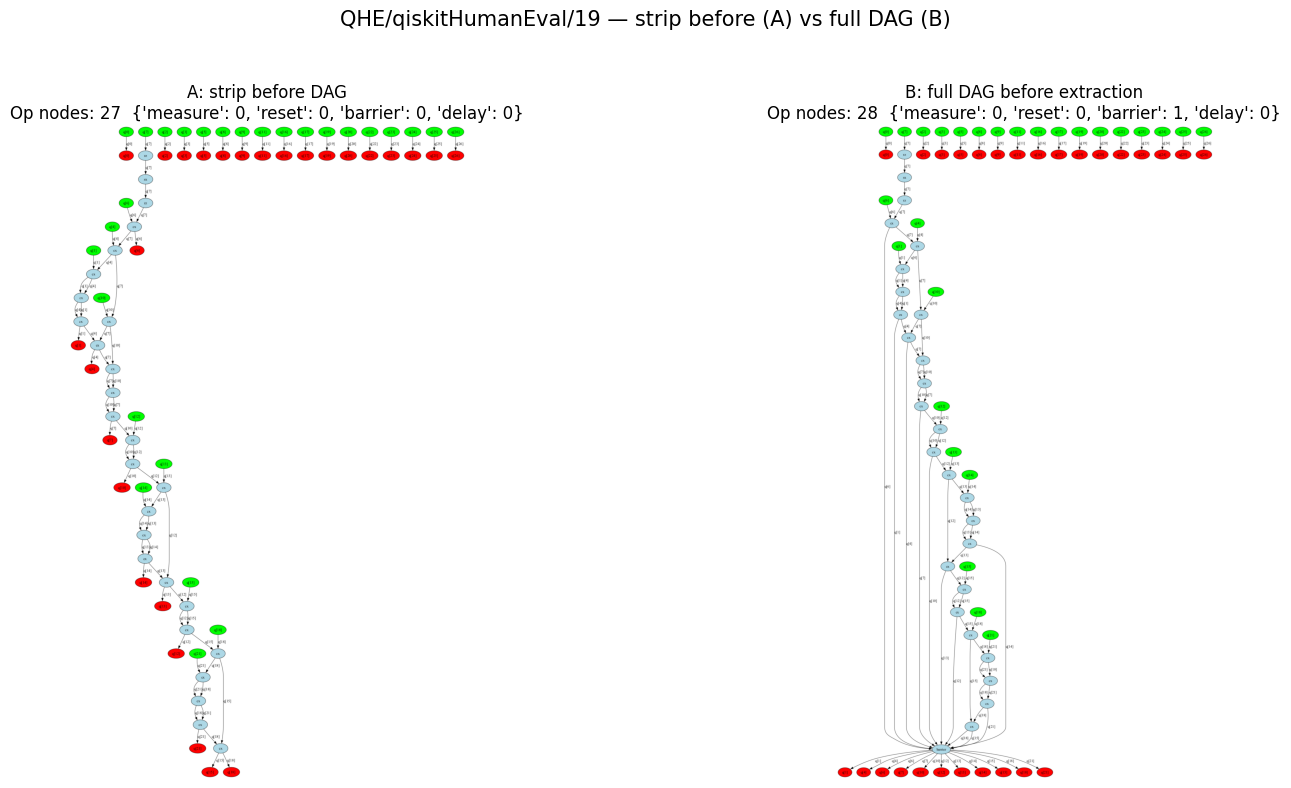

QHE/qiskitHumanEval/20 | A: {'measure': 0, 'reset': 0, 'barrier': 0, 'delay': 0}
QHE/qiskitHumanEval/20 | B: {'measure': 0, 'reset': 0, 'barrier': 1, 'delay': 0}


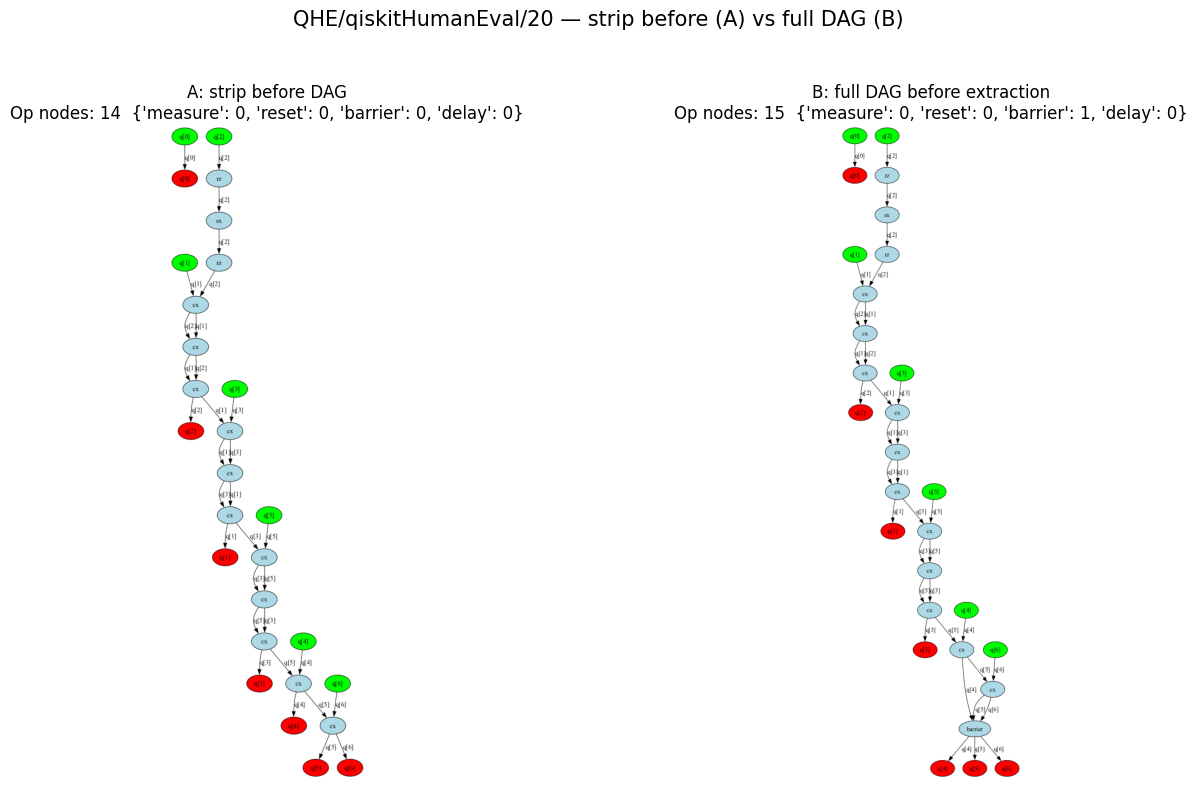

QHE/qiskitHumanEval/51 | A: {'measure': 0, 'reset': 0, 'barrier': 0, 'delay': 0}
QHE/qiskitHumanEval/51 | B: {'measure': 3, 'reset': 0, 'barrier': 4, 'delay': 0}


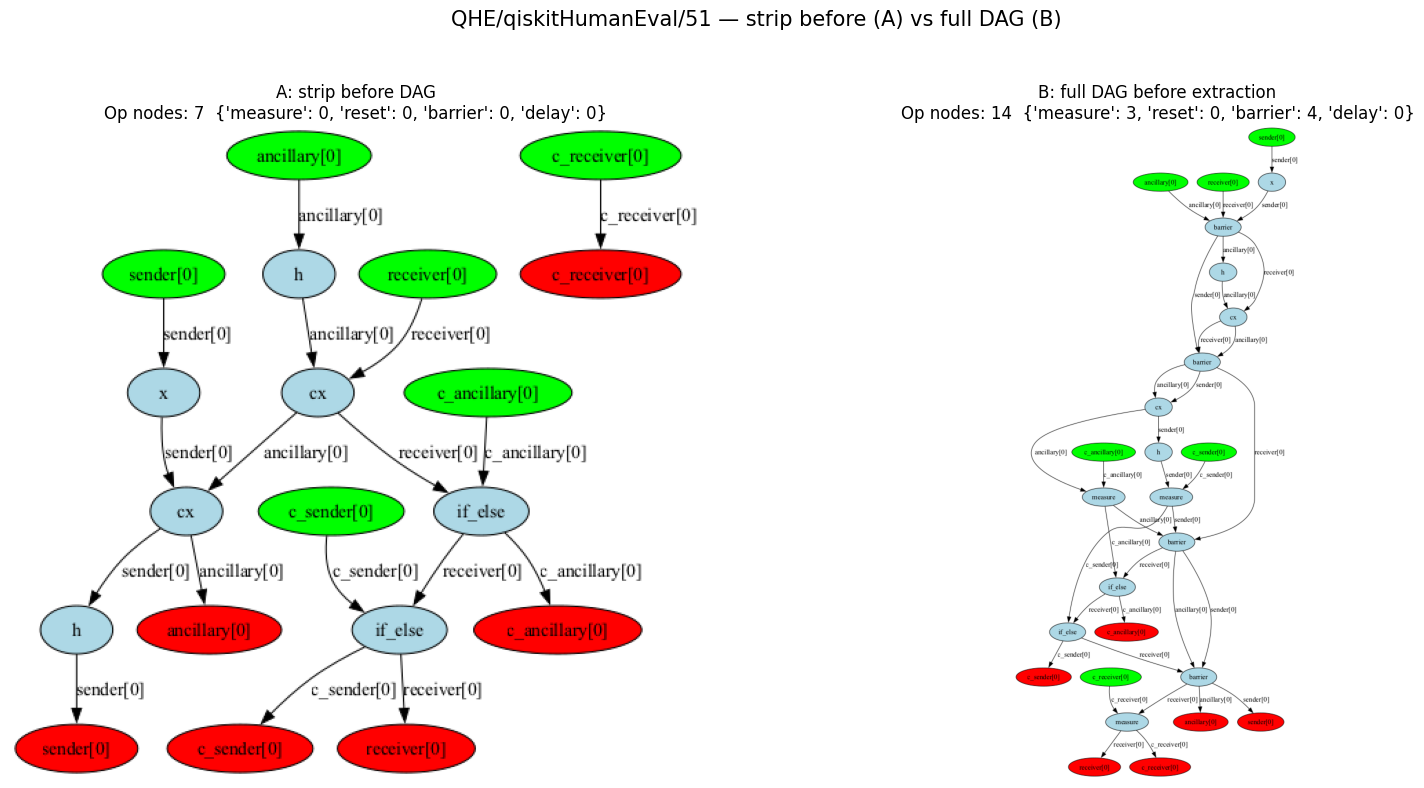

QHE/qiskitHumanEval/52 | A: {'measure': 0, 'reset': 0, 'barrier': 0, 'delay': 0}
QHE/qiskitHumanEval/52 | B: {'measure': 2, 'reset': 0, 'barrier': 2, 'delay': 0}


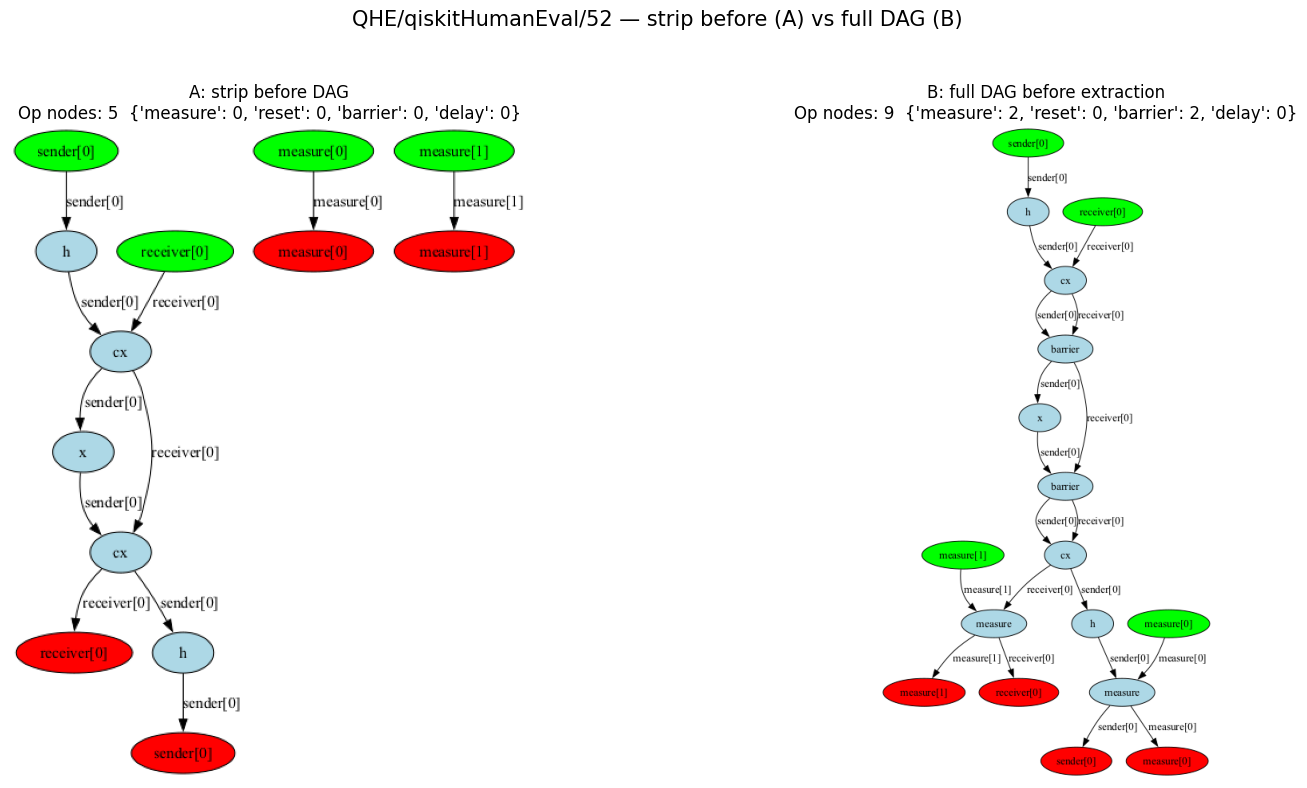

QHE/qiskitHumanEval/64 | A: {'measure': 0, 'reset': 0, 'barrier': 0, 'delay': 0}
QHE/qiskitHumanEval/64 | B: {'measure': 3, 'reset': 0, 'barrier': 2, 'delay': 0}


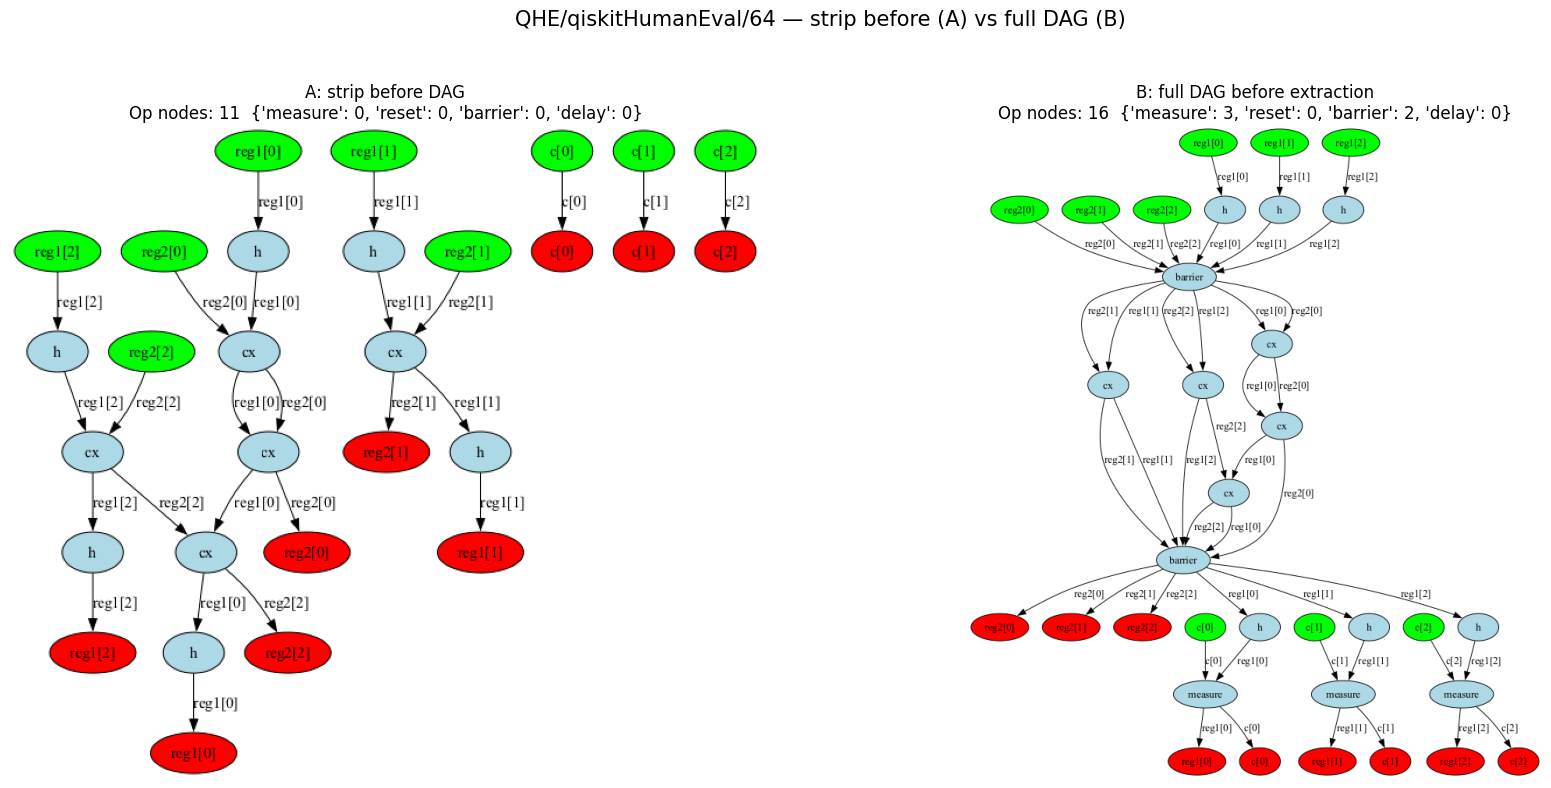

QHE/qiskitHumanEval/67 | A: {'measure': 0, 'reset': 0, 'barrier': 0, 'delay': 0}
QHE/qiskitHumanEval/67 | B: {'measure': 2, 'reset': 0, 'barrier': 1, 'delay': 0}


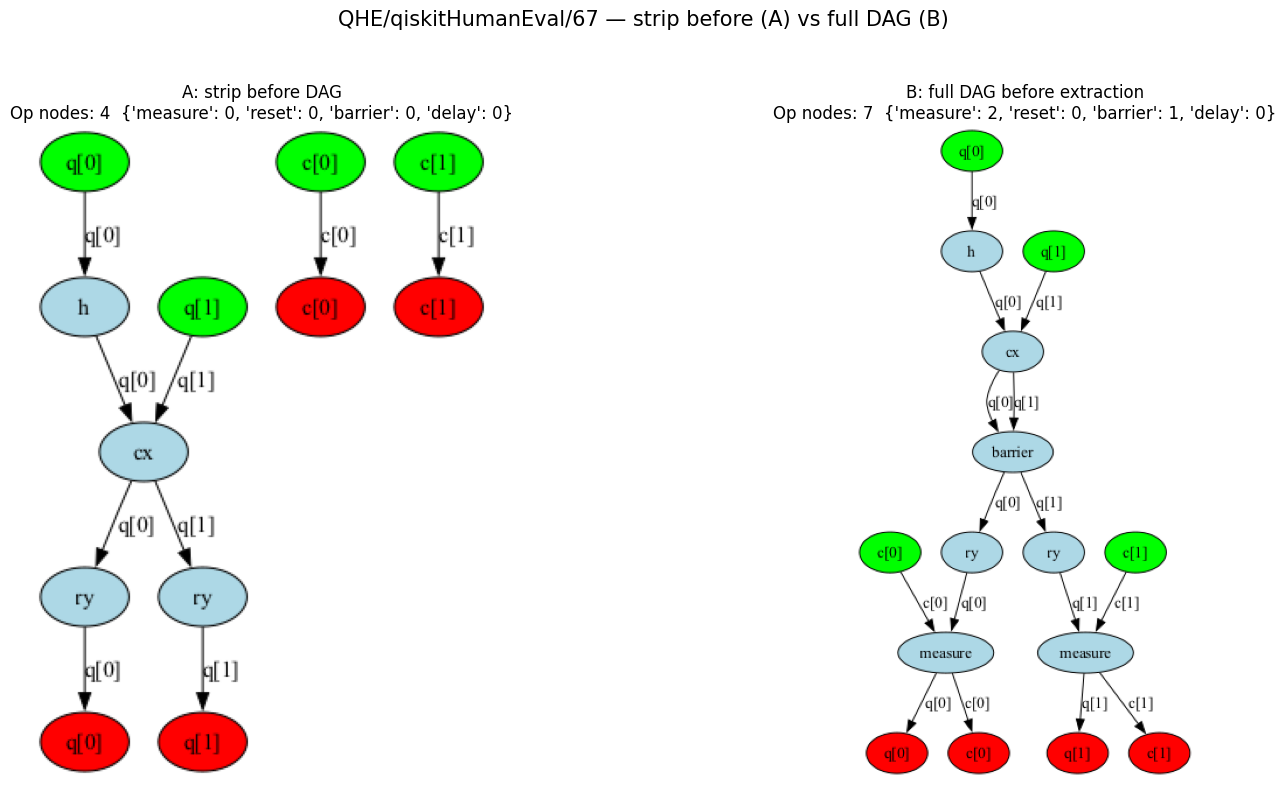

QHE/qiskitHumanEval/87 | A: {'measure': 0, 'reset': 0, 'barrier': 0, 'delay': 0}
QHE/qiskitHumanEval/87 | B: {'measure': 0, 'reset': 0, 'barrier': 0, 'delay': 1}


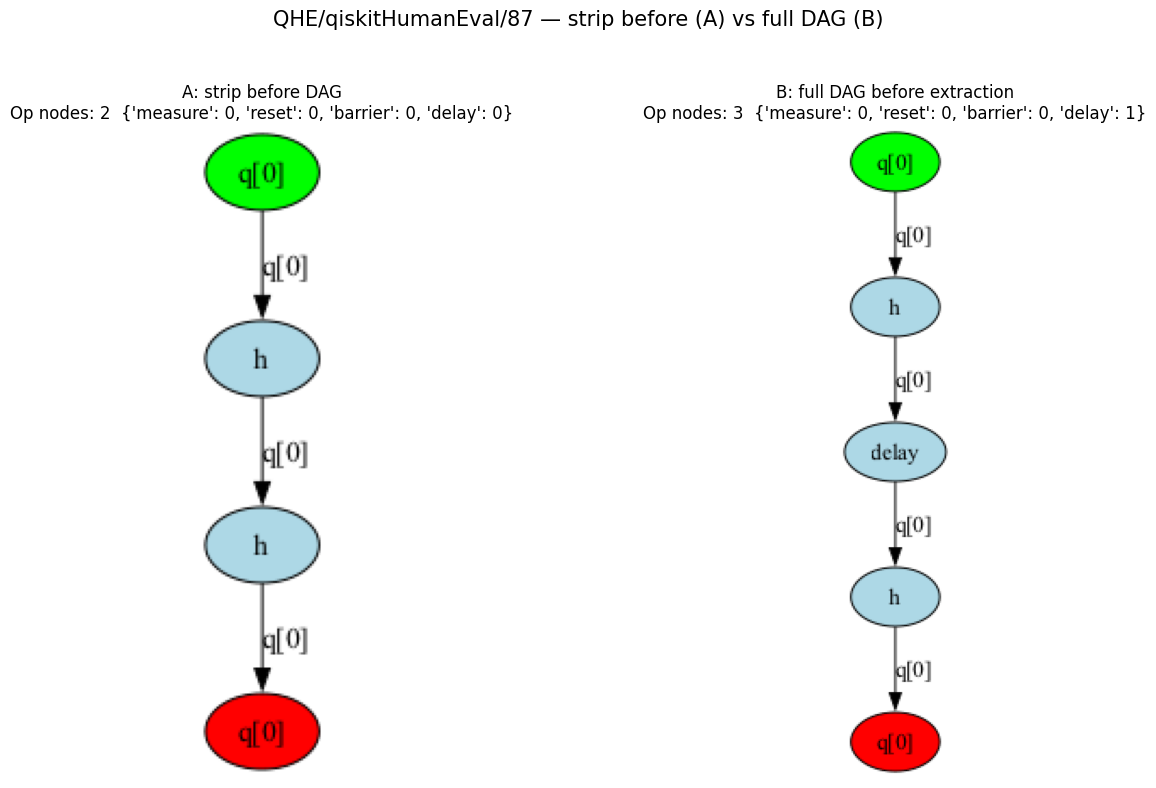

QB/23 | A: {'measure': 0, 'reset': 0, 'barrier': 0, 'delay': 0}
QB/23 | B: {'measure': 3, 'reset': 0, 'barrier': 7, 'delay': 0}


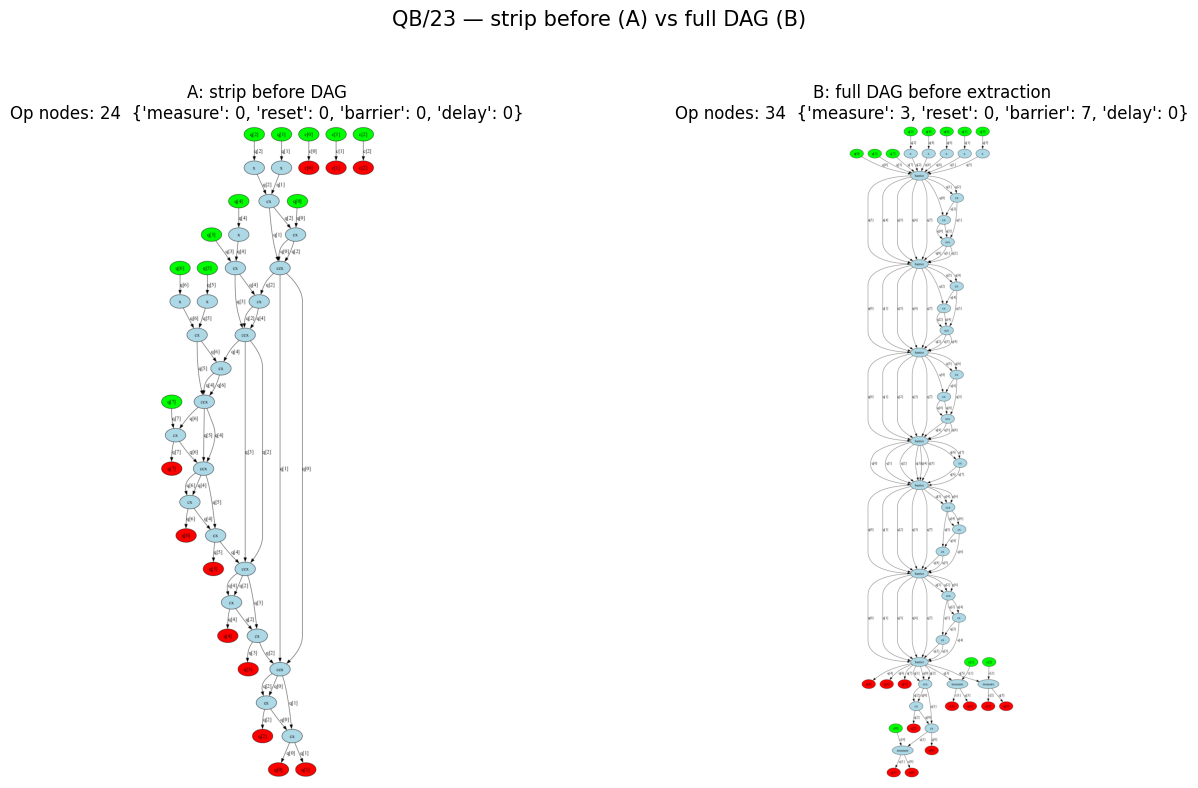

QB/29 | A: {'measure': 0, 'reset': 0, 'barrier': 0, 'delay': 0}
QB/29 | B: {'measure': 2, 'reset': 0, 'barrier': 1, 'delay': 0}


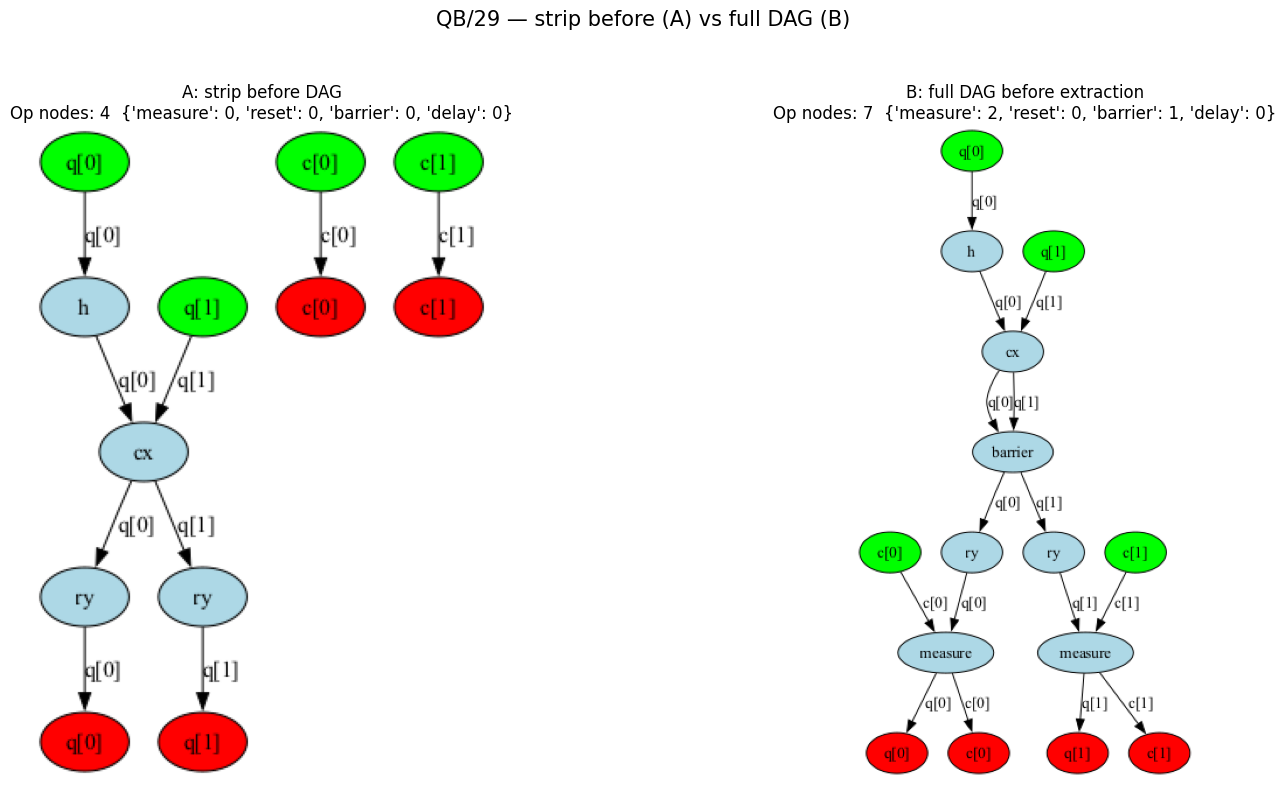

QB/33 | A: {'measure': 0, 'reset': 0, 'barrier': 0, 'delay': 0}
QB/33 | B: {'measure': 2, 'reset': 1, 'barrier': 0, 'delay': 0}


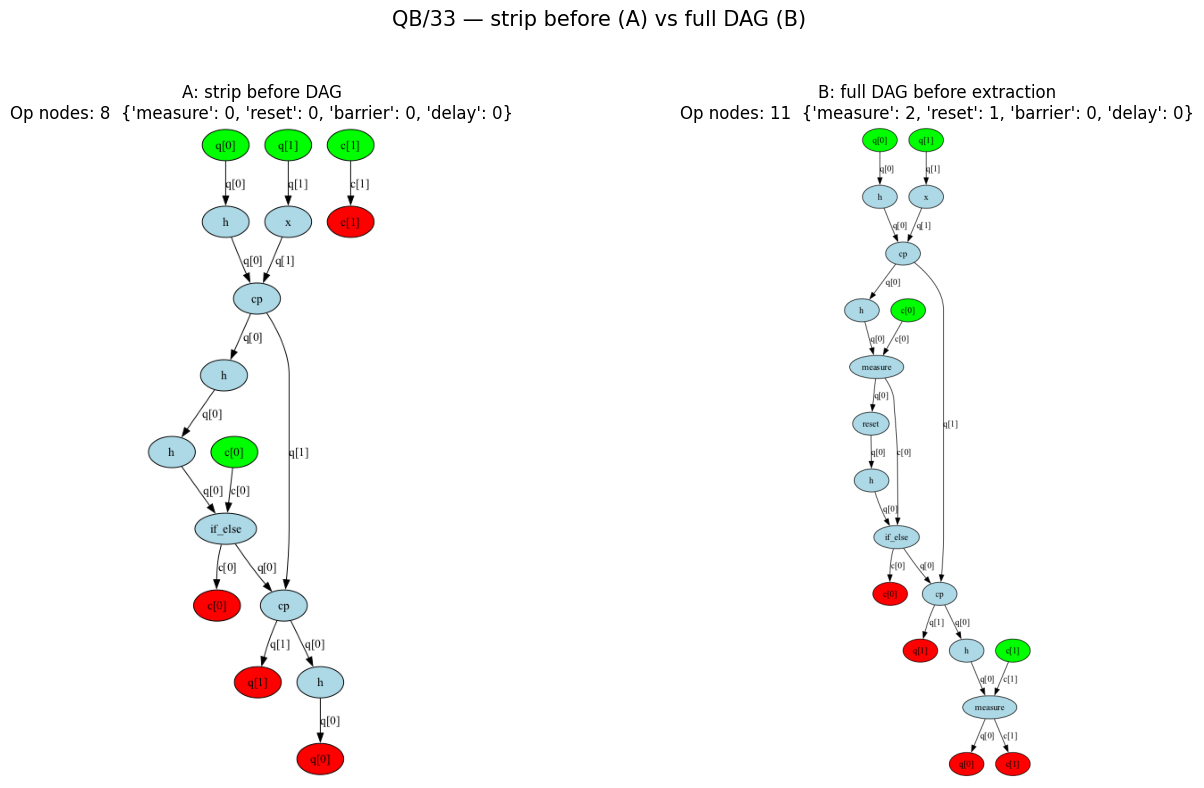

QB/34 | A: {'measure': 0, 'reset': 0, 'barrier': 0, 'delay': 0}
QB/34 | B: {'measure': 3, 'reset': 2, 'barrier': 0, 'delay': 0}


lib/pathplan/shortest.c:333: triangulation failed
lib/pathplan/shortest.c:203: cannot find triangle path
lib/pathplan/shortest.c:333: triangulation failed
lib/pathplan/shortest.c:203: cannot find triangle path


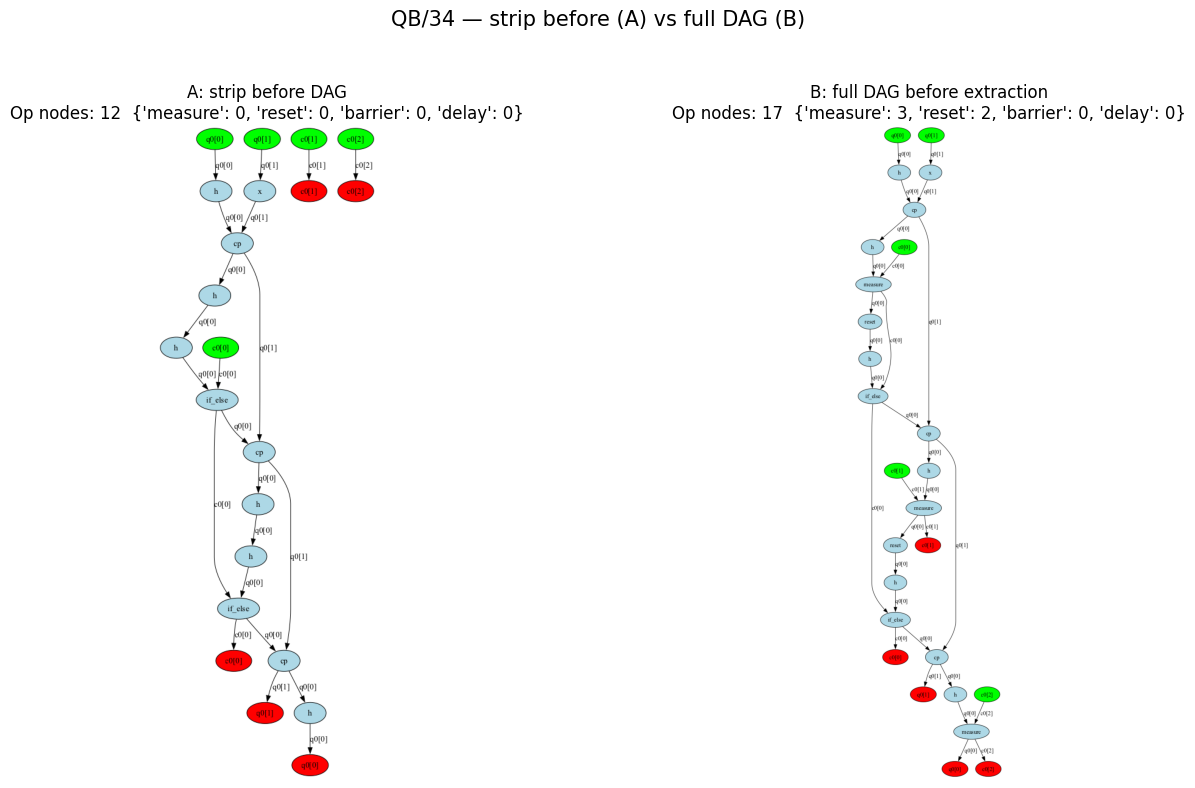

DAG saved to: /Users/milly/Desktop/LLM-based-Q-generation/temporary_dag_comparison


In [5]:
import os
os.environ['PATH'] = '/opt/homebrew/bin:' + os.environ.get('PATH', '')

from pathlib import Path
import re

import matplotlib.pyplot as plt
from PIL import Image
from qiskit.converters import circuit_to_dag
from qiskit.visualization import dag_drawer

assert "TEMP_DAG_CIRCUITS" in globals(), "请先运行修改后的临时测试单元"

DAG_OUTPUT_DIR = Path(PROJECT_DIR) / "temporary_dag_comparison"
DAG_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DAG_DRAW_ERRORS = []

tasks = list(dict.fromkeys(
    task for task, mode, method in TEMP_DAG_CIRCUITS
))

for task in tasks:
    safe_task = re.sub(r"[^A-Za-z0-9_-]+", "_", task)

    key_A = (task, "raw", "A")
    key_B = (task, "raw", "B")

    if key_A not in TEMP_DAG_CIRCUITS or key_B not in TEMP_DAG_CIRCUITS:
        print(f"skip {task}: A / B not in TEMP_DAG_CIRCUITS")
        continue

    fig, axes = plt.subplots(1, 2, figsize=(18, 8))

    for ax, (method, key) in zip(axes, (("A", key_A), ("B", key_B))):
        qc = TEMP_DAG_CIRCUITS[key][0]  # reference circuit
        dag = circuit_to_dag(qc)

        try:
            image_path = DAG_OUTPUT_DIR / f"{safe_task}_{method}.png"
            dag_drawer(dag, filename=str(image_path), style="color")
            with Image.open(image_path) as img:
                ax.imshow(img.copy())
            ax.axis('off')
            excluded_counts = {
                name: int(qc.count_ops().get(name, 0))
                for name in ("measure", "reset", "barrier", "delay")
            }
            ax.set_title(
                f"{method}: {'strip before DAG' if method == 'A' else 'full DAG before extraction'}\n"
                f"Op nodes: {len(dag.op_nodes())}  {excluded_counts}",
                fontsize=12,
            )
            print(f"{task} | {method}: {excluded_counts}")
        except Exception as exc:
            error = {
                "task": task, "method": method,
                "error": f"{type(exc).__name__}: {exc}",
            }
            DAG_DRAW_ERRORS.append(error)
            print(error)

    fig.suptitle(f"{task} — strip before (A) vs full DAG (B)", fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(str(DAG_OUTPUT_DIR / f"{safe_task}_comparison.png"))
    plt.show()

print("DAG saved to:", DAG_OUTPUT_DIR)
